# 🧠 Mental Health Crisis Prediction — Step-by-Step Guide
A beginner-friendly walkthrough. **Run each cell with Shift+Enter**, read the output, then continue. Every step has a 💡 note explaining what happened.

By the end you will have trained five models, explained them with SHAP, validated across datasets, and saved all figures — using synthetic data that mimics the real GLOBEM dataset.

## Step 0 — Install & import
Colab already has these libraries. Locally, uncomment the pip line.

In [1]:
# Colab already has most of these; this is a no-op there. Run once locally.
# !pip install -q numpy pandas scikit-learn matplotlib seaborn xgboost shap imbalanced-learn joblib
print('Dependencies ready.')

Dependencies ready.


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')
pd.set_option('display.width', 120)
RANDOM_STATE = 42
print('numpy', np.__version__, '| pandas', pd.__version__)

numpy 2.4.6 | pandas 3.0.3


> 💡 **What just happened:** We loaded NumPy/Pandas and fixed a random seed (42) so every run is reproducible — you and your supervisor get identical numbers.

## Step 1 — What are we predicting?
**Target:** will this person's PHQ-9 depression score cross 10 in the next 48–72 hours? This is **binary classification**: 1 = crisis, 0 = no crisis. We use *yesterday's* and *the day before's* behaviour to predict *tomorrow* — a genuine early-warning system.

## Step 2 — Define the features

In [3]:
def lag_names(features):
    """Return the lag-1 and lag-2 column names for a list of features."""
    return [f"{f}_lag1" for f in features] + [f"{f}_lag2" for f in features]

RAW_FEATURES = [
    "sleep_hours", "sleep_onset", "step_count", "hrv_ms",
    "screen_total", "screen_night", "loc_entropy", "call_freq",
]
DERIVED_FEATURES = ["sleep_irregularity", "activity_collapse", "social_isolation"]
ALL_FEATURES = RAW_FEATURES + DERIVED_FEATURES            # 11 features
COMMON_FEATURES = ["sleep_hours", "sleep_onset", "step_count",
                   "loc_entropy", "call_freq"]            # shared w/ StudentLife
PHQ9_CRISIS_THRESHOLD = 10
ALL_LAG_FEATURES = lag_names(ALL_FEATURES)                # 22 model inputs
COMMON_LAG_FEATURES = lag_names(COMMON_FEATURES)          # 10 cross-dataset inputs
print(f"{len(ALL_LAG_FEATURES)} lag features feed the model")

22 lag features feed the model


> 💡 **What just happened:** 8 phone/wearable signals + 3 engineered signals = 11 features. Each is copied to 'yesterday' (lag1) and 'two days ago' (lag2), giving the 22 numbers the model actually sees.

## Step 3 — Get the data
If real GLOBEM CSVs (`INS-W_1.csv`…`INS-W_4.csv`) are present we use them; otherwise we generate realistic synthetic data with the same structure.

In [4]:
def make_synthetic_globem(n_users=120, days=120, seed=RANDOM_STATE):
    """Generate a GLOBEM-structured daily dataframe with realistic behaviour.

    Crisis episodes are injected as multi-day windows in which behaviour
    deteriorates (less sleep, irregular bedtime, fewer steps, lower HRV, more
    night screen time, lower location entropy, fewer calls). The PHQ-9 label is
    derived from the *underlying* behaviour, so a genuine signal exists in the
    lagged features for the model to learn — without it being a trivial copy.
    """
    rng = np.random.default_rng(seed)
    rows = []

    for uid in range(n_users):
        # Per-user baselines (people differ from each other).
        base = {
            "sleep_hours": rng.normal(7.5, 0.6),
            "sleep_onset": rng.normal(0.0, 0.4),
            "step_count": rng.normal(8000, 1500),
            "hrv_ms": rng.normal(70, 12),
            "screen_total": rng.normal(3.5, 0.8),
            "screen_night": rng.normal(0.4, 0.2),
            "loc_entropy": rng.normal(0.7, 0.12),
            "call_freq": rng.normal(7, 2),
        }

        # A latent "distress" level performs a slow random walk; episodes are
        # periods where it crosses a threshold.
        distress = np.zeros(days)
        d = rng.normal(0.0, 0.3)
        for t in range(days):
            d += rng.normal(0.0, 0.25)
            d *= 0.92  # mean reversion
            # Occasionally kick into an episode.
            if rng.random() < 0.015:
                d += rng.uniform(1.5, 3.0)
            distress[t] = d
        distress = np.clip(distress, 0, None)

        for t in range(days):
            k = distress[t]  # 0 = well, larger = worse
            row = {
                "user_id": uid,
                "day": t,
                "sleep_hours": base["sleep_hours"] - 0.9 * k + rng.normal(0, 0.4),
                "sleep_onset": base["sleep_onset"] + 0.6 * k + rng.normal(0, 0.25),
                "step_count": base["step_count"] * (1 - 0.18 * k) + rng.normal(0, 600),
                "hrv_ms": base["hrv_ms"] - 9 * k + rng.normal(0, 5),
                "screen_total": base["screen_total"] + 0.7 * k + rng.normal(0, 0.5),
                "screen_night": base["screen_night"] + 0.45 * k + rng.normal(0, 0.15),
                "loc_entropy": base["loc_entropy"] - 0.12 * k + rng.normal(0, 0.05),
                "call_freq": base["call_freq"] * (1 - 0.22 * k) + rng.normal(0, 1),
                "_distress": k,
            }
            rows.append(row)

    df = pd.DataFrame(rows)

    # Physical bounds.
    df["sleep_hours"] = df["sleep_hours"].clip(2, 13)
    df["step_count"] = df["step_count"].clip(0, 25000)
    df["hrv_ms"] = df["hrv_ms"].clip(10, 140)
    df["screen_total"] = df["screen_total"].clip(0, 16)
    df["screen_night"] = df["screen_night"].clip(0, 6)
    df["loc_entropy"] = df["loc_entropy"].clip(0, 1)
    df["call_freq"] = df["call_freq"].clip(0, None).round()

    # PHQ-9 generated from accumulated recent distress, plus a *non-linear*
    # compounding term: crisis risk spikes when several behavioural channels are
    # simultaneously bad (short sleep AND high night-screen AND low activity).
    # This threshold/interaction structure is what real crisis onset looks like
    # and is where tree ensembles beat linear models.
    roll = df.groupby("user_id")["_distress"].transform(
        lambda s: s.rolling(7, min_periods=1).mean()
    )

    def _relu_z(col, sign):
        z = (df[col] - df[col].mean()) / (df[col].std() + 1e-9)
        return np.clip(sign * z, 0, None)  # only the "bad" direction counts

    short_sleep = _relu_z("sleep_hours", -1)     # bad when LOW
    night_screen = _relu_z("screen_night", +1)   # bad when HIGH
    low_activity = _relu_z("step_count", -1)     # bad when LOW
    interaction = (
        2.0 * short_sleep * night_screen        # two-way compounding
        + 1.5 * short_sleep * low_activity
    )

    phq9 = 4 + 4.0 * roll + 1.3 * interaction + rng.normal(0, 1.5, len(df))
    df["phq9"] = phq9.clip(0, 27).round().astype(int)

    # Inject ~5% missing values into raw features to exercise imputation.
    for f in RAW_FEATURES:
        mask = rng.random(len(df)) < 0.05
        df.loc[mask, f] = np.nan

    df = df.drop(columns=["_distress"])
    return df.sort_values(["user_id", "day"]).reset_index(drop=True)

FEATURE_PATTERNS = {'sleep_hours': [['sleep', 'asleep', 'duration'],
                 ['sleep', 'duration', 'main'],
                 ['sleep', 'asleep'],
                 ['sleep', 'duration']],
 'sleep_onset': [['sleep', 'starttime', 'main'],
                 ['sleep', 'bedtime'],
                 ['sleep', 'onset'],
                 ['sleep', 'starttime']],
 'step_count': [['steps', 'sumsteps'], ['steps', 'count'], ['steps', 'sum']],
 'hrv_ms': [['heartrate', 'hrv'],
            ['hrv'],
            ['heartrate', 'resting'],
            ['heartrate', 'restinghr'],
            ['heartrate']],
 'screen_total': [['screen', 'sumduration', 'unlock'],
                  ['screen', 'duration', 'unlock'],
                  ['screen', 'unlock'],
                  ['screen', 'duration']],
 'screen_night': [['screen', 'unlock', 'night'],
                  ['screen', 'duration', 'night'],
                  ['screen', 'night']],
 'loc_entropy': [['locations', 'entropy'], ['location', 'entropy'], ['loc', 'entropy']],
 'call_freq': [['calls', 'count'], ['call', 'count'], ['call', 'freq']]}
FEATURE_EXCLUDE = {'screen_total': ('night',)}
LABEL_KEYWORDS = ['phq9', 'phq', 'dep_weekly', 'dep_endterm', 'depression', 'dep', 'bdi']
PID_KEYWORDS = ['pid', 'participant', 'uid', 'user', 'subject']
DATE_KEYWORDS = ['local_date', 'date', 'day', 'timestamp']

def _resolve_column(columns, keyword_sets, exclude=()):
    """First column matching any keyword set (all keywords as substrings),
    preferring the 'allday' time segment, then the shortest (most aggregate)
    name. Returns None if nothing matches."""
    lowered = {c: str(c).lower() for c in columns}
    for kws in keyword_sets:
        cands = [
            c for c, cl in lowered.items()
            if all(k in cl for k in kws) and not any(e in cl for e in exclude)
        ]
        if cands:
            cands.sort(key=lambda c: (0 if "allday" in str(c).lower() else 1, len(str(c))))
            return cands[0]
    return None

def _first_present(columns, keywords):
    """First column whose lowercased name contains any of the keywords."""
    lowered = {c: str(c).lower() for c in columns}
    for kw in keywords:
        for c, cl in lowered.items():
            if kw in cl:
                return c
    return None

def _map_real_globem(raw, label_threshold=PHQ9_CRISIS_THRESHOLD, verbose=True):
    """Map a raw GLOBEM dataframe to our canonical schema via keyword matching.

    Handles: id/date detection, resilient feature resolution, weekly→daily label
    carry-forward (GLOBEM surveys are weekly while sensors are daily), and
    conversion of binary / PHQ / BDI labels into a PHQ-9-equivalent ``phq9``
    column so the downstream ``crisis = phq9 >= threshold`` rule is preserved.
    """
    pid = _first_present(raw.columns, PID_KEYWORDS)
    date = _first_present(raw.columns, DATE_KEYWORDS)
    if pid is None or date is None:
        raise ValueError(f"could not locate id/date columns (id={pid}, date={date})")

    out = pd.DataFrame(index=raw.index)
    out["user_id"] = raw[pid].astype(str)
    out["date"] = pd.to_datetime(raw[date], errors="coerce")
    out = out.dropna(subset=["date"])

    # Resolve the 8 raw features.
    resolved = {}
    for feat, patterns in FEATURE_PATTERNS.items():
        col = _resolve_column(raw.columns, patterns, exclude=FEATURE_EXCLUDE.get(feat, ()))
        resolved[feat] = col
        out[feat] = pd.to_numeric(raw.loc[out.index, col], errors="coerce") if col else np.nan

    # Resolve the label column and convert to a PHQ-9-equivalent score.
    label_col = _resolve_column(raw.columns, [[k] for k in LABEL_KEYWORDS])
    if label_col is None:
        raise ValueError("no depression / PHQ-9 label column found")
    label = pd.to_numeric(raw.loc[out.index, label_col], errors="coerce")
    name = str(label_col).lower()
    nonnull = label.dropna()
    is_binary = len(nonnull) > 0 and set(nonnull.unique()).issubset({0, 1})
    if is_binary:                       # already a crisis flag
        out["phq9"] = np.where(label.isna(), np.nan,
                               np.where(label > 0, float(label_threshold), 0.0))
    elif "bdi" in name:                 # Beck Depression Inventory -> moderate cutoff 20
        out["phq9"] = np.where(label.isna(), np.nan,
                               np.where(label >= 20, float(label_threshold), 0.0))
    else:                               # PHQ-9 (or PHQ-like) continuous score
        out["phq9"] = label

    # Weekly survey -> carry the most recent score forward across that week's
    # daily sensor rows, then drop days before the first survey.
    out = out.sort_values(["user_id", "date"])
    out["phq9"] = out.groupby("user_id")["phq9"].ffill(limit=7)
    out = out.dropna(subset=["phq9"]).reset_index(drop=True)

    # Per-user ordinal day index (lags operate on date-sorted rows).
    out["day"] = out.groupby("user_id").cumcount()

    if verbose:
        print("  Resolved GLOBEM columns:")
        for feat in RAW_FEATURES:
            col = resolved.get(feat)
            print(f"    {feat:<14} <- {col if col else 'MISSING (imputed)'}")
        print(f"    {'label':<14} <- {label_col}  "
              f"({'binary' if is_binary else 'bdi' if 'bdi' in name else 'phq-like'})")

    return out.sort_values(["user_id", "day"]).reset_index(drop=True)

def load_globem(data_dir=".", verbose=True):
    """Load real GLOBEM INS-W_*.csv files if present, else synthetic data.

    Returns (df, is_real). The real-data path uses a keyword-based column
    resolver (``_map_real_globem``) that survives GLOBEM naming variations
    across releases — you should not need to hard-code column strings. If the
    mapping fails we fall back to synthetic data so the notebook always runs.
    """
    files = [os.path.join(data_dir, f"INS-W_{i}.csv") for i in range(1, 5)]
    present = [f for f in files if os.path.exists(f)]
    if not present:
        print("No real GLOBEM CSVs found -> using synthetic GLOBEM-structured data.")
        return make_synthetic_globem(), False

    print(f"Found {len(present)} real GLOBEM file(s): {[os.path.basename(f) for f in present]}")
    raw = pd.concat([pd.read_csv(f) for f in present], ignore_index=True)
    try:
        df = _map_real_globem(raw, verbose=verbose)
        print(f"Mapped real GLOBEM data: {df.shape[0]} user-days, "
              f"{df['user_id'].nunique()} users, crisis rate "
              f"{(df['phq9'] >= PHQ9_CRISIS_THRESHOLD).mean():.3f}.")
        return df, True
    except Exception as exc:  # noqa: BLE001
        print(f"Could not map real GLOBEM columns ({exc}); using synthetic data.")
        return make_synthetic_globem(), False

In [5]:
df, is_real = load_globem('.')
print('Using', 'REAL' if is_real else 'SYNTHETIC', 'data')
print(df.shape[0], 'user-days from', df['user_id'].nunique(), 'people')
df.head()

No real GLOBEM CSVs found -> using synthetic GLOBEM-structured data.
Using SYNTHETIC data


14400 user-days from 120 people


,user_id,day,sleep_hours,sleep_onset,step_count,hrv_ms,screen_total,screen_night,loc_entropy,call_freq,phq9
0,0,0,8.534529,-0.737849,8467.605447,90.471344,3.391705,0.000000,0.696928,7.0,4
1,0,1,8.374309,-0.662708,8978.510086,85.173464,2.156555,0.083141,0.708650,5.0,4
2,0,2,NaN,-0.330276,8847.986652,76.225422,2.352641,NaN,0.692649,6.0,5
3,0,3,NaN,-0.394425,8633.752551,82.546042,1.915667,0.469700,0.789699,7.0,5
4,0,4,7.377607,-0.694097,9840.362566,82.600523,2.179244,0.000000,0.761713,7.0,6


> 💡 **What just happened:** Each row = one person on one day. Columns are the raw sensor readings plus that week's PHQ-9 score. Notice some values are NaN (missing) — real sensors drop out, so we simulate that too.

## Step 4 — Fill in missing values (imputation)
Strategy: copy the last reading for short gaps, else use the person's own average, else the global average.

In [6]:
def impute(df):
    """Forward-fill short gaps, then personal mean, then global mean."""
    df = df.copy()
    df[RAW_FEATURES] = df.groupby("user_id")[RAW_FEATURES].transform(
        lambda x: x.ffill(limit=2)
    )
    personal = df.groupby("user_id")[RAW_FEATURES].transform("mean")
    df[RAW_FEATURES] = df[RAW_FEATURES].fillna(personal)
    df[RAW_FEATURES] = df[RAW_FEATURES].fillna(df[RAW_FEATURES].mean())
    return df

In [7]:
before = df[RAW_FEATURES].isna().sum().sum()
df = impute(df)
after = df[RAW_FEATURES].isna().sum().sum()
print(f'Missing values: {before} -> {after}')

Missing values: 5675 -> 0


> 💡 **What just happened:** We filled every gap. Using each person's *own* average is more honest than a population average — night owls stay night owls.

## Step 5 — Engineer 3 extra features
Raw sensors aren't enough. We compute **sleep irregularity** (how chaotic bedtimes are), **activity collapse** (% step drop vs personal baseline), and a **social isolation** index.

In [8]:
def derive_features(df):
    """Add the 3 engineered features (sleep irregularity, activity collapse,
    social isolation)."""
    df = df.copy()
    g = df.groupby("user_id", group_keys=False)

    # Sleep irregularity: rolling 7-day std of sleep onset (in minutes).
    df["sleep_irregularity"] = g["sleep_onset"].transform(
        lambda s: s.rolling(7, min_periods=2).std() * 60
    ).fillna(0)

    # Activity collapse: % drop vs personal 14-day rolling average steps.
    avg14 = g["step_count"].transform(lambda s: s.rolling(14, min_periods=3).mean())
    df["activity_collapse"] = ((avg14 - df["step_count"]) / avg14 * 100).clip(lower=0)
    df["activity_collapse"] = df["activity_collapse"].fillna(0)

    # Social isolation: mean of call-drop% and entropy-drop% vs 5-day average.
    call5 = g["call_freq"].transform(lambda s: s.rolling(5, min_periods=2).mean())
    ent5 = g["loc_entropy"].transform(lambda s: s.rolling(5, min_periods=2).mean())
    call_drop = ((call5 - df["call_freq"]) / call5.replace(0, np.nan) * 100).clip(lower=0)
    ent_drop = ((ent5 - df["loc_entropy"]) / ent5.replace(0, np.nan) * 100).clip(lower=0)
    df["social_isolation"] = (
        (call_drop.fillna(0) + ent_drop.fillna(0)) / 2
    )
    return df

In [9]:
df = derive_features(df)
df[['user_id','day'] + DERIVED_FEATURES].head()

,user_id,day,sleep_irregularity,activity_collapse,social_isolation
0,0,0,0.000000,0.000000,0.000000
1,0,1,3.187979,0.000000,8.333333
2,0,2,13.013991,0.000000,0.483248
3,0,3,11.953708,1.124731,0.000000
4,0,4,11.235963,0.000000,0.000000


> 💡 **What just happened:** These capture *change relative to a person's own normal* — a 50% step drop matters whether you usually walk 4,000 or 12,000 steps.

## Step 6 — Create the crisis label
PHQ-9 ≥ 10 becomes label 1 (crisis), below 10 becomes 0.

In [10]:
def add_label(df):
    """Binary crisis label from PHQ-9 >= threshold."""
    df = df.copy()
    df["crisis_label"] = (df["phq9"] >= PHQ9_CRISIS_THRESHOLD).astype(int)
    return df

In [11]:
df = add_label(df)
print(df['crisis_label'].value_counts())
print('crisis rate:', round(df['crisis_label'].mean(), 3))

crisis_label
0    11219
1     3181
Name: count, dtype: int64
crisis rate: 0.221


> 💡 **What just happened:** Far more no-crisis days than crisis days — this imbalance is why we later use SMOTE and judge models by AUC-ROC, not accuracy.

## Step 7 — Make the 48-hour lag features
Shift each feature back 1 and 2 days, then drop the first 2 days per person (no history yet).

In [12]:
def make_lags(df, features=ALL_FEATURES):
    """Create lag-1 and lag-2 features per user and drop rows with NaN lags.

    The model is trained ONLY on lag features (no same-day data), which is what
    makes this a genuine 48-hour-ahead predictor rather than same-day detection.
    """
    df = df.copy()
    g = df.groupby("user_id")
    for f in features:
        df[f"{f}_lag1"] = g[f].shift(1)
        df[f"{f}_lag2"] = g[f].shift(2)
    lags = lag_names(features)
    df = df.dropna(subset=lags).reset_index(drop=True)
    return df

In [13]:
ds = make_lags(df, features=ALL_FEATURES)
print('rows with full 2-day history:', len(ds))
ds[['user_id','day','crisis_label','sleep_hours_lag1','sleep_hours_lag2']].head()

rows with full 2-day history: 14160


,user_id,day,crisis_label,sleep_hours_lag1,sleep_hours_lag2
0,0,2,0,8.374309,8.534529
1,0,3,0,8.374309,8.374309
2,0,4,0,8.374309,8.374309
3,0,5,0,7.377607,8.374309
4,0,6,0,7.238658,7.377607


> 💡 **What just happened:** The model now only ever sees PAST data to predict the FUTURE label — no cheating with same-day values.

## Step 8 — Split, scale, and balance
Split by *person* (group-aware) so no one is in both train and test. Scale to [0,1] (fit on train only). Balance the training set with SMOTE.

In [14]:
def split_normalise_balance(df, feature_cols=ALL_LAG_FEATURES, test_size=0.25):
    """Group-aware split (no user in both sides), fit scaler on train only,
    SMOTE on train only. Returns a dict of arrays + the fitted scaler."""
    from sklearn.model_selection import GroupShuffleSplit
    from sklearn.preprocessing import MinMaxScaler
    from imblearn.over_sampling import SMOTE

    X = df[feature_cols].values
    y = df["crisis_label"].values
    groups = df["user_id"].values

    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=RANDOM_STATE)
    train_idx, test_idx = next(gss.split(X, y, groups))
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = MinMaxScaler().fit(X_train)            # fit on TRAIN only
    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)

    smote = SMOTE(random_state=RANDOM_STATE)        # balance TRAIN only
    X_train_bal, y_train_bal = smote.fit_resample(X_train_s, y_train)

    return {
        "X_train": X_train_s,
        "X_test": X_test_s,
        "y_train": y_train,
        "y_test": y_test,
        "X_train_bal": X_train_bal,
        "y_train_bal": y_train_bal,
        "scaler": scaler,
        "feature_cols": feature_cols,
    }

In [15]:
data = split_normalise_balance(ds)
print('train rows:', len(data['y_train']),
      '| after SMOTE:', len(data['y_train_bal']),
      '| test rows:', len(data['y_test']))

train rows: 10620 | after SMOTE: 16520 | test rows: 3540


> 💡 **What just happened:** SMOTE invents *synthetic* crisis examples (not copies) so the model sees a 50/50 balance and stops ignoring the rare crisis class. The test set is left untouched so our score is honest.

## Step 9 — Train all five models
From a simple Logistic Regression baseline up to XGBoost.

In [16]:
def build_models(scale_pos_weight=5.67):
    """Return the five models with the handoff's hyper-parameters."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.svm import SVC
    from sklearn.ensemble import RandomForestClassifier
    import xgboost as xgb

    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=6, min_samples_leaf=5,
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "SVM": SVC(
            kernel="rbf", probability=True,
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=150, max_depth=6, min_samples_leaf=5,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ),
        "XGBoost": xgb.XGBClassifier(
            n_estimators=200, learning_rate=0.05, objective="binary:logistic",
            max_depth=6, min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
            reg_alpha=0.1, reg_lambda=1.0, gamma=0.1,
            scale_pos_weight=scale_pos_weight, eval_metric="auc",
            random_state=RANDOM_STATE,
        ),
    }

def evaluate(model, X_test, y_test):
    """Compute the standard metric set for one fitted model."""
    from sklearn.metrics import (
        accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    )
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba),
    }

def train_all(data):
    """Train all five models on the balanced training set; evaluate on test.

    Returns (results_df, fitted_models, proba_dict)."""
    models = build_models()
    results, fitted, probas = [], {}, {}
    for name, model in models.items():
        model.fit(data["X_train_bal"], data["y_train_bal"])
        metrics = evaluate(model, data["X_test"], data["y_test"])
        metrics["Model"] = name
        results.append(metrics)
        fitted[name] = model
        probas[name] = model.predict_proba(data["X_test"])[:, 1]
    cols = ["Model", "Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
    results_df = pd.DataFrame(results)[cols].sort_values("AUC-ROC").reset_index(drop=True)
    return results_df, fitted, probas

def cross_validate_auc(df, feature_cols=ALL_LAG_FEATURES, n_splits=5):
    """Stratified 5-fold CV AUC for XGBoost (sanity check on stability)."""
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import roc_auc_score
    from sklearn.preprocessing import MinMaxScaler
    from imblearn.over_sampling import SMOTE

    X = df[feature_cols].values
    y = df["crisis_label"].values
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    aucs = []
    for tr, te in skf.split(X, y):
        scaler = MinMaxScaler().fit(X[tr])
        Xtr, Xte = scaler.transform(X[tr]), scaler.transform(X[te])
        Xtr_b, ytr_b = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr, y[tr])
        model = build_models()["XGBoost"]
        model.fit(Xtr_b, ytr_b)
        aucs.append(roc_auc_score(y[te], model.predict_proba(Xte)[:, 1]))
    return np.array(aucs)

In [17]:
results_df, fitted, probas = train_all(data)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Decision Tree,0.862,0.655,0.825,0.730,0.913
1,SVM,0.890,0.722,0.837,0.775,0.933
2,XGBoost,0.855,0.629,0.881,0.734,0.934
3,Random Forest,0.892,0.728,0.838,0.779,0.945
4,Logistic Regression,0.892,0.716,0.866,0.784,0.947


> 💡 **What just happened:** Read the **AUC-ROC** column — it measures how well each model ranks a real crisis above a non-crisis day, regardless of threshold. 0.50 = coin flip, 1.0 = perfect.

In [18]:
cv = cross_validate_auc(ds)
print(f'XGBoost cross-validated AUC: {cv.mean():.3f} ± {cv.std():.3f}')

XGBoost cross-validated AUC: 0.939 ± 0.005


> 💡 **What just happened:** 5-fold cross-validation confirms the score is stable, not a lucky single split.

## Step 10 — Does it generalise? (cross-dataset)
Train on GLOBEM's shared features, test zero-shot on a phone-only StudentLife-like cohort.

In [19]:
def build_dataset(df, features=ALL_FEATURES):
    """Run the full preprocessing chain up to (but not including) the split."""
    df = impute(df)
    df = derive_features(df)
    df = add_label(df)
    df = make_lags(df, features=features)
    return df

def make_synthetic_studentlife(n_users=40, days=70, seed=7):
    """Phone-only dataset sharing the 5 common features (no Fitbit, no night
    screen). Same generator family, different cohort/seed."""
    df = make_synthetic_globem(n_users=n_users, days=days, seed=seed)
    # Drop wearable/night-screen signals not available in StudentLife.
    df = df.drop(columns=["hrv_ms", "screen_night", "screen_total"], errors="ignore")
    return df

def impute_common(df):
    df = df.copy()
    df[COMMON_FEATURES] = df.groupby("user_id")[COMMON_FEATURES].transform(
        lambda x: x.ffill(limit=2)
    )
    personal = df.groupby("user_id")[COMMON_FEATURES].transform("mean")
    df[COMMON_FEATURES] = df[COMMON_FEATURES].fillna(personal)
    df[COMMON_FEATURES] = df[COMMON_FEATURES].fillna(df[COMMON_FEATURES].mean())
    return df

def derive_common(df):
    """Cross-dataset derives only use common-feature inputs (no Fitbit)."""
    df = df.copy()
    g = df.groupby("user_id", group_keys=False)
    df["sleep_irregularity"] = g["sleep_onset"].transform(
        lambda s: s.rolling(7, min_periods=2).std() * 60
    ).fillna(0)
    return df

def cross_dataset_validation(globem_df):
    """Train a reduced XGBoost on GLOBEM common features, apply zero-shot to a
    StudentLife-like set. Returns (auc_globem, auc_studentlife)."""
    from sklearn.preprocessing import MinMaxScaler
    from imblearn.over_sampling import SMOTE
    from sklearn.metrics import roc_auc_score

    # GLOBEM reduced to common features.
    g = build_dataset(globem_df.copy(), features=COMMON_FEATURES)
    Xg = g[COMMON_LAG_FEATURES].values
    yg = g["crisis_label"].values

    scaler = MinMaxScaler().fit(Xg)
    Xg_s = scaler.transform(Xg)
    Xg_b, yg_b = SMOTE(random_state=RANDOM_STATE).fit_resample(Xg_s, yg)
    model = build_models()["XGBoost"]
    model.fit(Xg_b, yg_b)
    auc_globem = roc_auc_score(yg, model.predict_proba(Xg_s)[:, 1])

    # StudentLife: build same common lag features, scale with GLOBEM scaler.
    sl = make_synthetic_studentlife()
    # add_label needs phq9 -> present from generator.
    sl = impute_common(sl)
    sl = derive_common(sl)
    sl = add_label(sl)
    sl = make_lags(sl, features=COMMON_FEATURES)
    Xs = scaler.transform(sl[COMMON_LAG_FEATURES].values)
    ys = sl["crisis_label"].values
    auc_sl = roc_auc_score(ys, model.predict_proba(Xs)[:, 1])
    return auc_globem, auc_sl

In [20]:
auc_globem, auc_sl = cross_dataset_validation(df)
print(f'GLOBEM {auc_globem:.3f} -> StudentLife {auc_sl:.3f} '
      f'(drop {auc_globem - auc_sl:.3f}; ≤0.08 is good)')

GLOBEM 0.965 -> StudentLife 0.932 (drop 0.033; ≤0.08 is good)


> 💡 **What just happened:** A small drop means the model learned *universal* behavioural signs of deterioration, not patterns unique to one study.

## Step 11 — Explain the model with SHAP
Which signals drove the predictions?

In [21]:
def shap_importance(model, X, feature_cols):
    """Mean |SHAP| per feature, sorted descending."""
    import shap
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X)
    mean_abs = np.abs(values).mean(axis=0)
    return (
        pd.DataFrame({"feature": feature_cols, "mean_abs_shap": mean_abs})
        .sort_values("mean_abs_shap", ascending=False)
        .reset_index(drop=True)
    ), values

In [22]:
shap_df, shap_values = shap_importance(
    fitted['XGBoost'], data['X_test'], data['feature_cols'])
shap_df.head(10)

,feature,mean_abs_shap
0,screen_night_lag1,0.921414
1,sleep_hours_lag1,0.718328
2,sleep_hours_lag2,0.437436
3,screen_night_lag2,0.398717
4,sleep_onset_lag1,0.324463
5,call_freq_lag2,0.257438
6,loc_entropy_lag2,0.255477
7,social_isolation_lag2,0.230631
8,call_freq_lag1,0.210889
9,hrv_ms_lag1,0.184716


> 💡 **What just happened:** A clinician can now see *why* an alert fired (e.g. 'sleep dropped and night phone use rose two days ago') instead of trusting a black box.

## Step 12 — Save figures and the model
Creates all 8 figures (300 DPI) plus the trained model, scaler and CSV results under `outputs/`.

In [23]:
def _fig_dir(out_dir):
    path = os.path.join(out_dir, "figures")
    os.makedirs(path, exist_ok=True)
    return path

def generate_figures(ds, data, results_df, fitted, probas, shap_df, shap_values,
                     auc_globem, auc_sl, out_dir="outputs"):
    """Render the 8 project figures. Returns list of saved paths."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import roc_curve, confusion_matrix

    sns.set_theme(style="whitegrid")
    fig_dir = _fig_dir(out_dir)
    saved = []

    def _save(fig, name):
        path = os.path.join(fig_dir, name)
        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.close(fig)
        saved.append(path)

    # fig1: feature distributions by class (6 representative raw features).
    feats = ["sleep_hours", "step_count", "hrv_ms", "screen_night",
             "loc_entropy", "call_freq"]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, f in zip(axes.ravel(), feats):
        for label, color in [(0, "#4c72b0"), (1, "#c44e52")]:
            sub = ds[ds["crisis_label"] == label][f]
            ax.hist(sub, bins=30, alpha=0.6, color=color,
                    label=("Crisis" if label else "No crisis"), density=True)
        ax.set_title(f)
        ax.legend(fontsize=8)
    fig.suptitle("Fig 1 — Feature distributions by class", fontsize=14)
    fig.tight_layout()
    _save(fig, "fig1_distributions.png")

    # fig2: before/after normalisation (first 6 lag features).
    cols = data["feature_cols"][:6]
    raw_X = ds[cols].values
    scaled_X = data["scaler"].transform(ds[data["feature_cols"]].values)[:, :6]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].boxplot(raw_X, labels=[c[:10] for c in cols])
    axes[0].set_title("Before normalisation (raw scales)")
    axes[0].tick_params(axis="x", rotation=45)
    axes[1].boxplot(scaled_X, labels=[c[:10] for c in cols])
    axes[1].set_title("After Min-Max normalisation [0,1]")
    axes[1].tick_params(axis="x", rotation=45)
    fig.suptitle("Fig 2 — Effect of Min-Max normalisation", fontsize=14)
    fig.tight_layout()
    _save(fig, "fig2_normalisation.png")

    # fig3: before/after SMOTE class balance.
    before = np.bincount(data["y_train"])
    after = np.bincount(data["y_train_bal"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].bar(["No crisis", "Crisis"], before, color=["#4c72b0", "#c44e52"])
    axes[0].set_title(f"Before SMOTE  ({before[1]}/{before.sum()} crisis)")
    axes[1].bar(["No crisis", "Crisis"], after, color=["#4c72b0", "#c44e52"])
    axes[1].set_title(f"After SMOTE  ({after[1]}/{after.sum()} crisis)")
    fig.suptitle("Fig 3 — SMOTE class balancing (training set only)", fontsize=14)
    fig.tight_layout()
    _save(fig, "fig3_smote.png")

    # fig4: correlation heatmap of the 11 same-day features.
    fig, ax = plt.subplots(figsize=(10, 8))
    corr = ds[ALL_FEATURES].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                square=True, cbar_kws={"shrink": 0.8}, ax=ax, annot_kws={"size": 7})
    ax.set_title("Fig 4 — Feature correlation heatmap")
    fig.tight_layout()
    _save(fig, "fig4_correlation.png")

    # fig5: ROC curves for all models.
    fig, ax = plt.subplots(figsize=(8, 7))
    for name in probas:
        fpr, tpr, _ = roc_curve(data["y_test"], probas[name])
        auc = float(results_df.loc[results_df["Model"] == name, "AUC-ROC"].iloc[0])
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random (0.50)")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title("Fig 5 — ROC curves (all models)")
    ax.legend(loc="lower right", fontsize=9)
    fig.tight_layout()
    _save(fig, "fig5_roc_curves.png")

    # fig6: confusion matrix for best model (by AUC).
    best = results_df.iloc[-1]["Model"]
    pred = (probas[best] >= 0.5).astype(int)
    cm = confusion_matrix(data["y_test"], pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No crisis", "Crisis"],
                yticklabels=["No crisis", "Crisis"], ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"Fig 6 — Confusion matrix ({best})")
    fig.tight_layout()
    _save(fig, "fig6_confusion_matrix.png")

    # fig7: SHAP global importance (top 15).
    top = shap_df.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(top["feature"], top["mean_abs_shap"], color="#55a868")
    ax.set_xlabel("Mean |SHAP value|")
    ax.set_title("Fig 7 — SHAP global feature importance (XGBoost)")
    fig.tight_layout()
    _save(fig, "fig7_shap.png")

    # fig8: cross-dataset AUC comparison.
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(["GLOBEM\n(train)", "StudentLife\n(zero-shot)"],
                  [auc_globem, auc_sl], color=["#4c72b0", "#dd8452"])
    ax.set_ylim(0, 1)
    ax.axhline(auc_globem - 0.08, ls="--", color="red", alpha=0.6,
               label="Acceptance floor (drop ≤ 0.08)")
    for b, v in zip(bars, [auc_globem, auc_sl]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
    ax.set_ylabel("AUC-ROC")
    ax.set_title(f"Fig 8 — Cross-dataset validation (drop={auc_globem-auc_sl:.3f})")
    ax.legend()
    fig.tight_layout()
    _save(fig, "fig8_cross_validation.png")

    return saved

def save_artifacts(fitted, scaler, results_df, shap_df, out_dir="outputs"):
    """Persist model, scaler, metrics CSV and SHAP CSV."""
    import joblib
    model_dir = os.path.join(out_dir, "models")
    os.makedirs(model_dir, exist_ok=True)
    joblib.dump(fitted["XGBoost"], os.path.join(model_dir, "xgboost_crisis_model.pkl"))
    joblib.dump(scaler, os.path.join(model_dir, "minmax_scaler.pkl"))
    results_df.to_csv(os.path.join(out_dir, "model_results.csv"), index=False)
    shap_df.to_csv(os.path.join(out_dir, "shap_importance.csv"), index=False)

In [24]:
paths = generate_figures(ds, data, results_df, fitted, probas,
                         shap_df, shap_values, auc_globem, auc_sl)
save_artifacts(fitted, data['scaler'], results_df, shap_df)
print('Saved', len(paths), 'figures and all artifacts.')

Saved 8 figures and all artifacts.


fig1_distributions.png


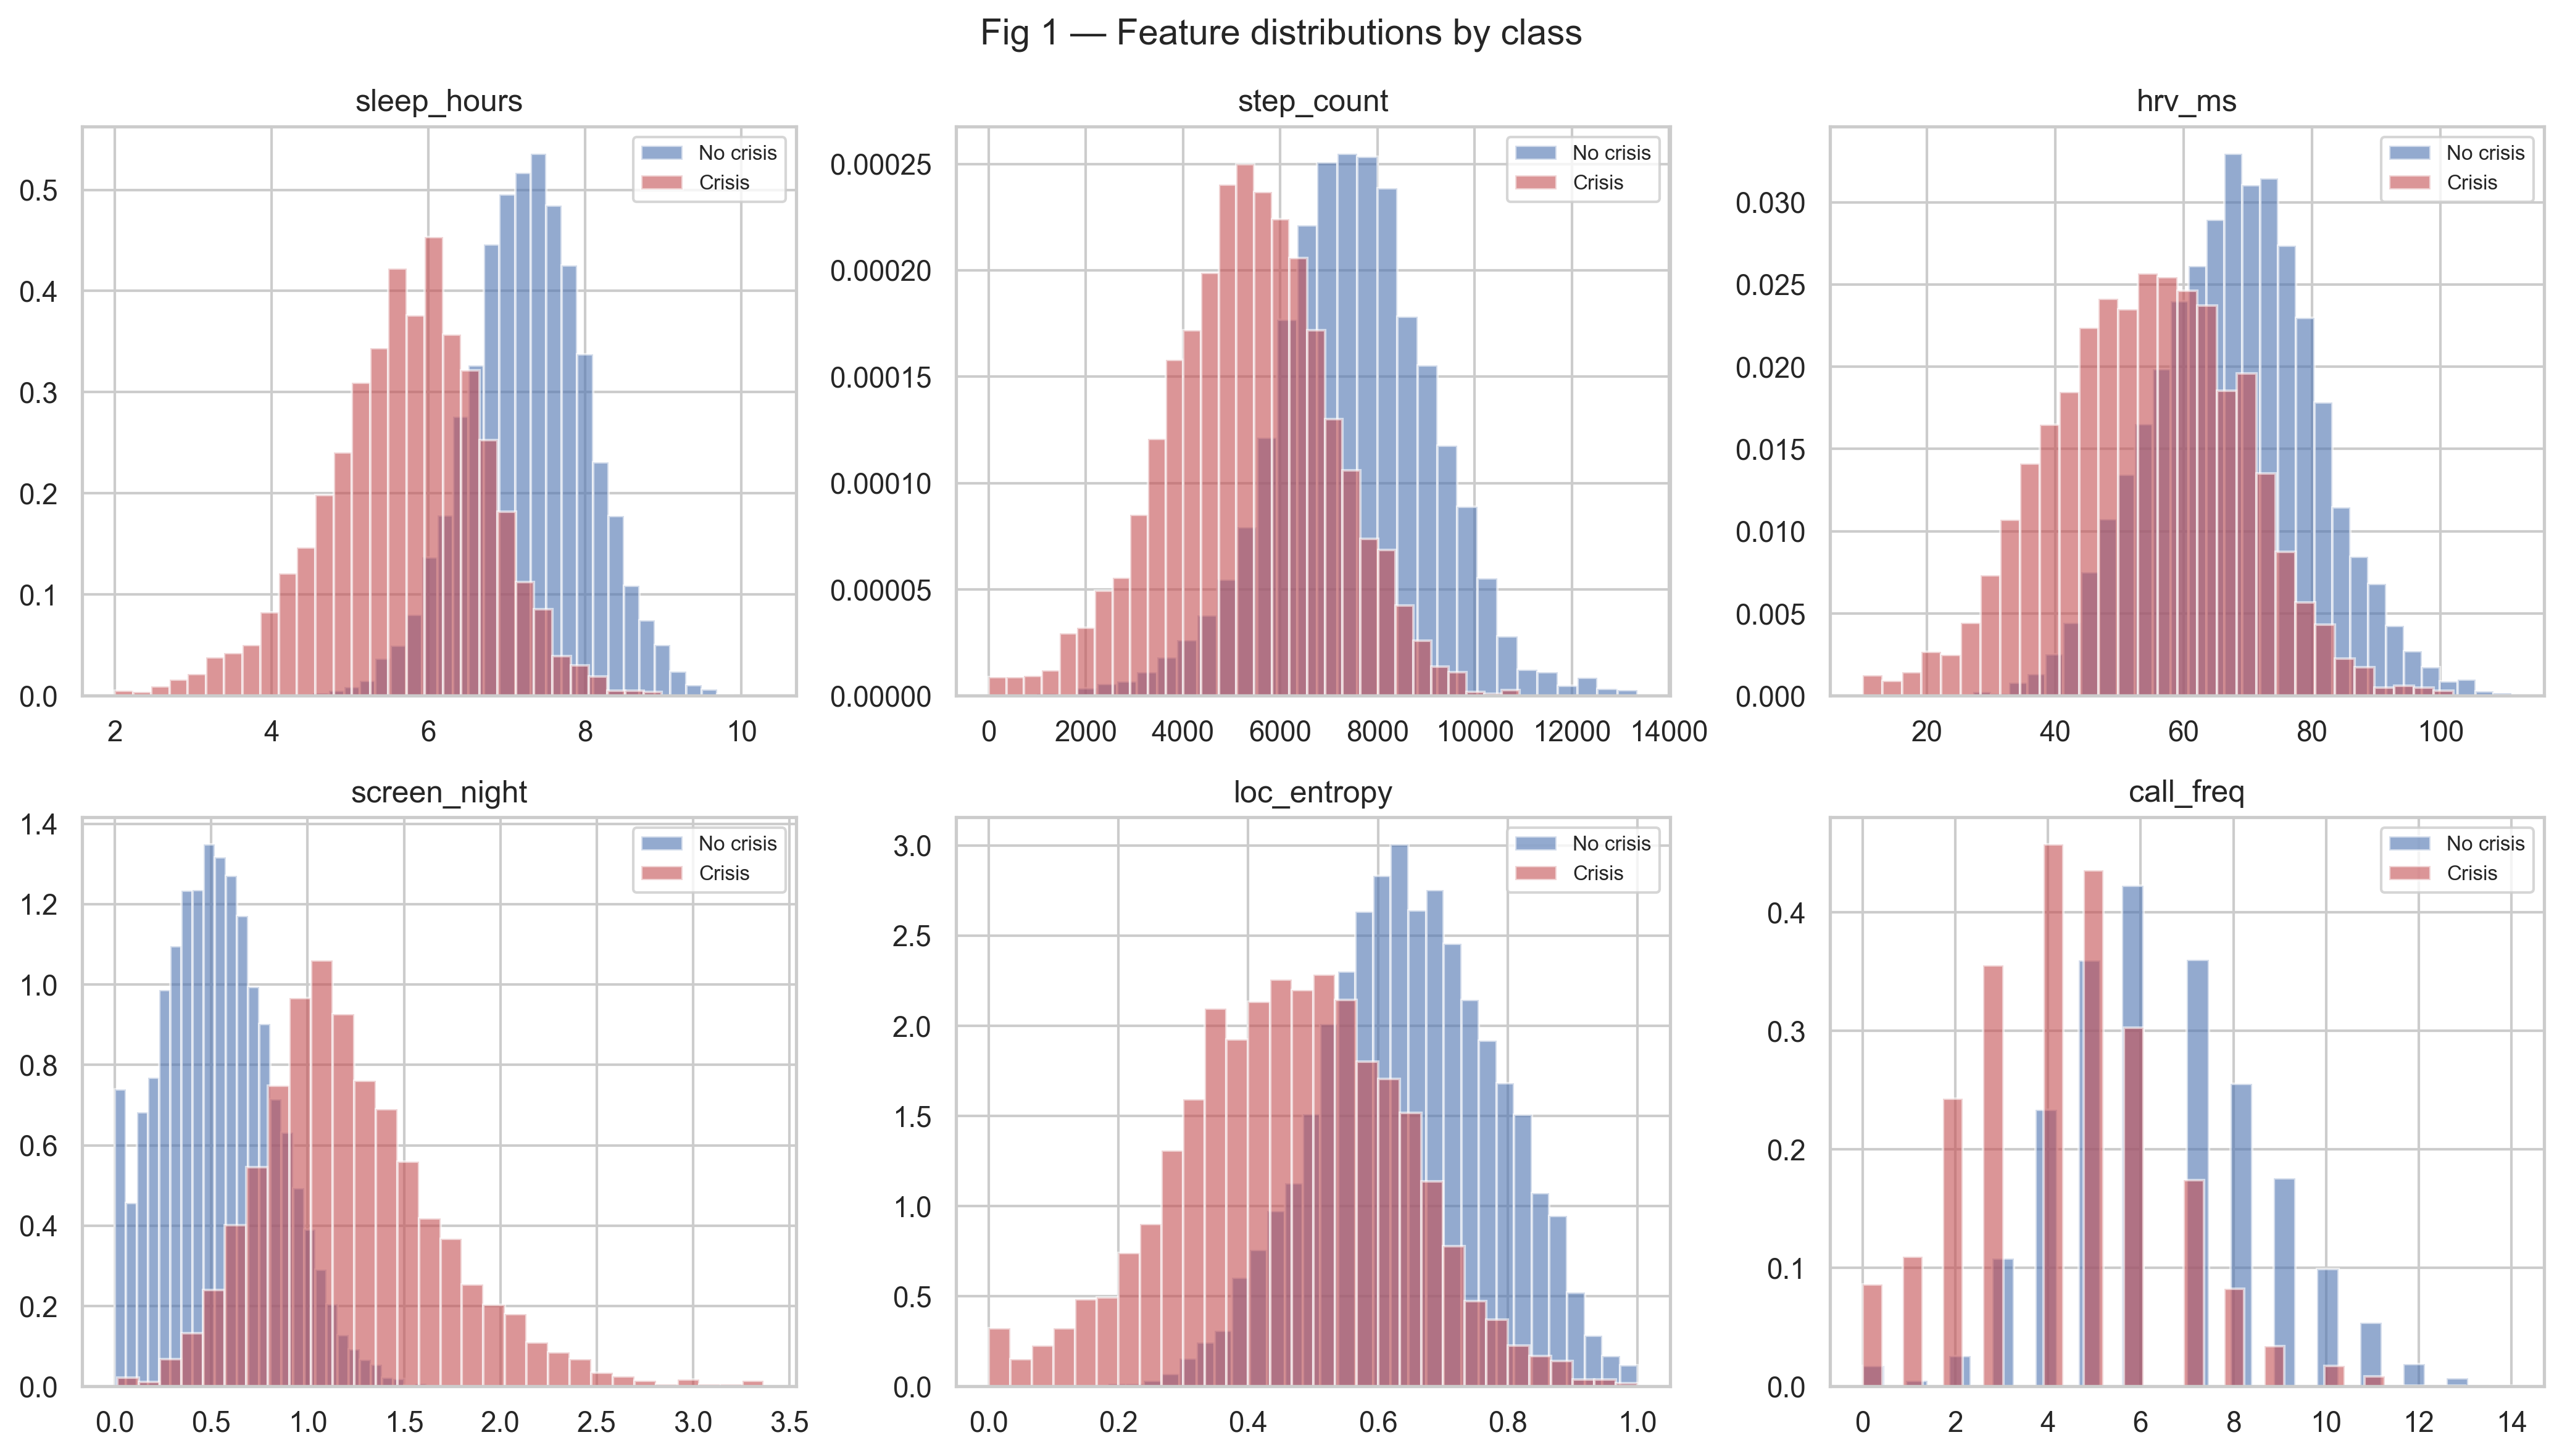

fig2_normalisation.png


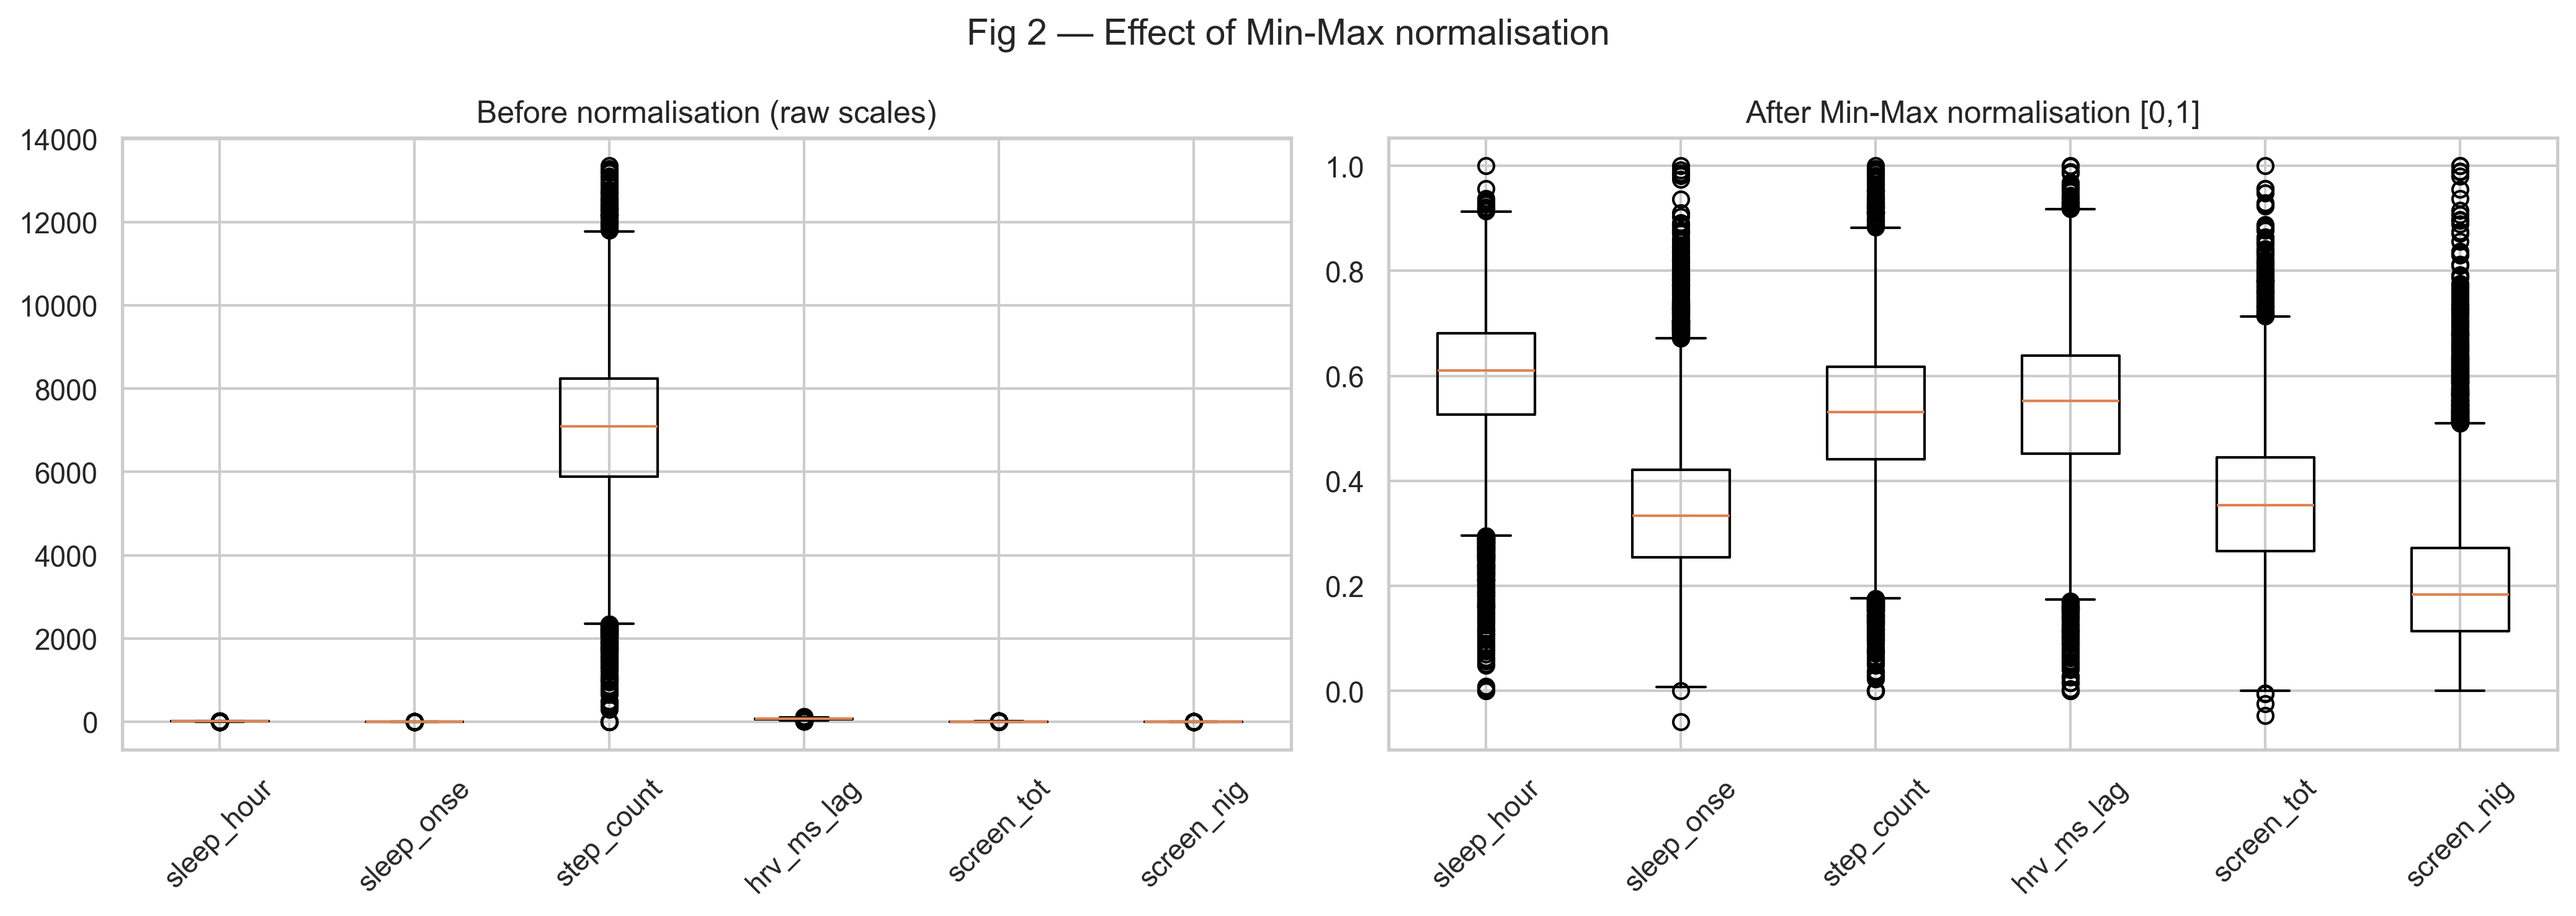

fig3_smote.png


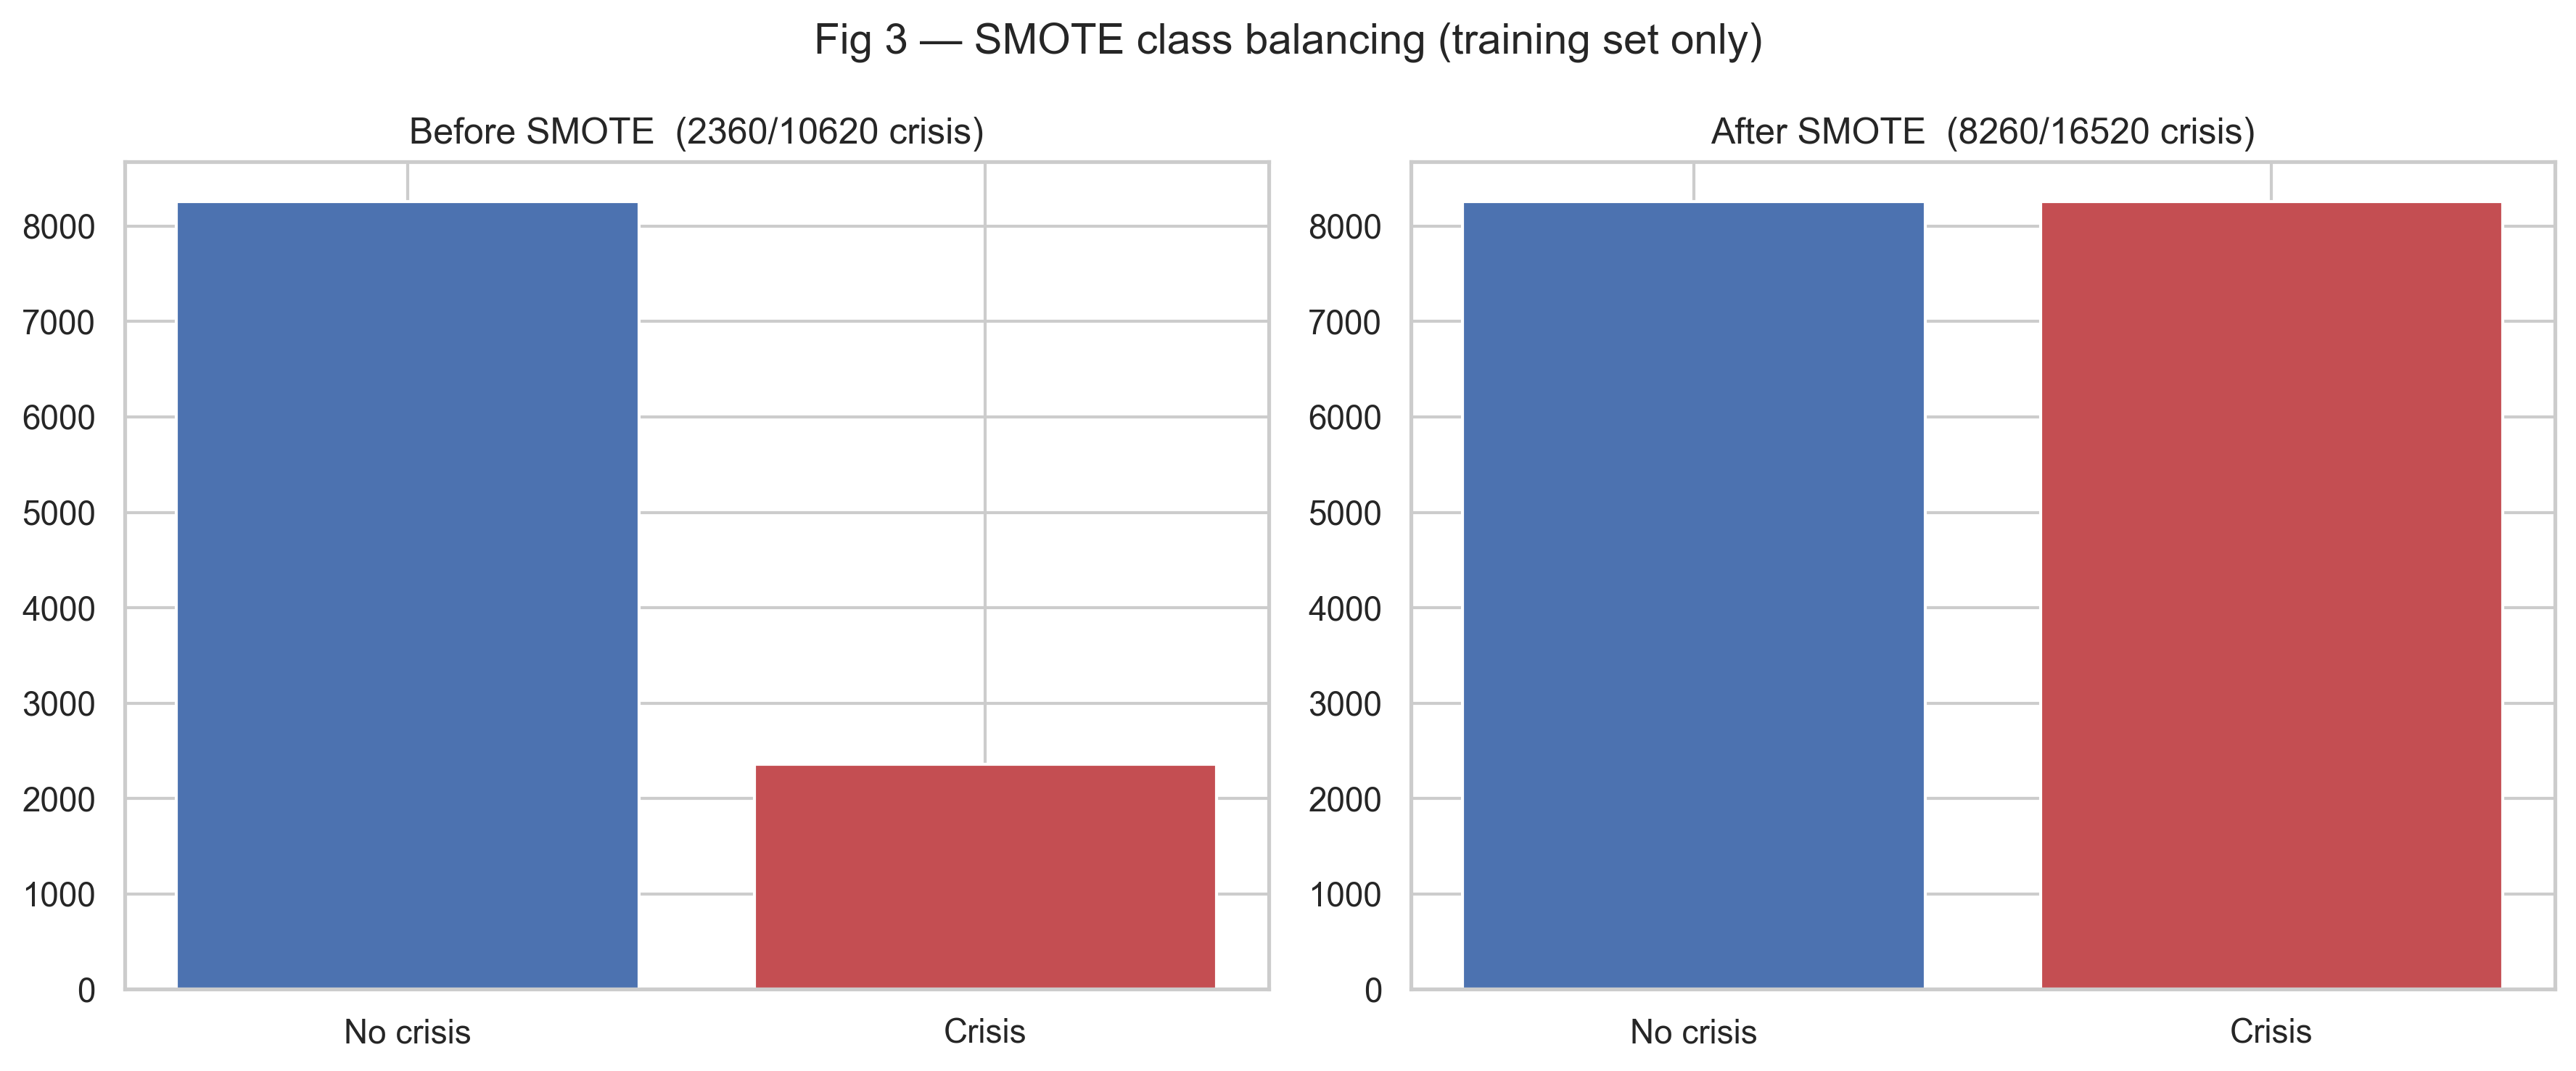

fig4_correlation.png


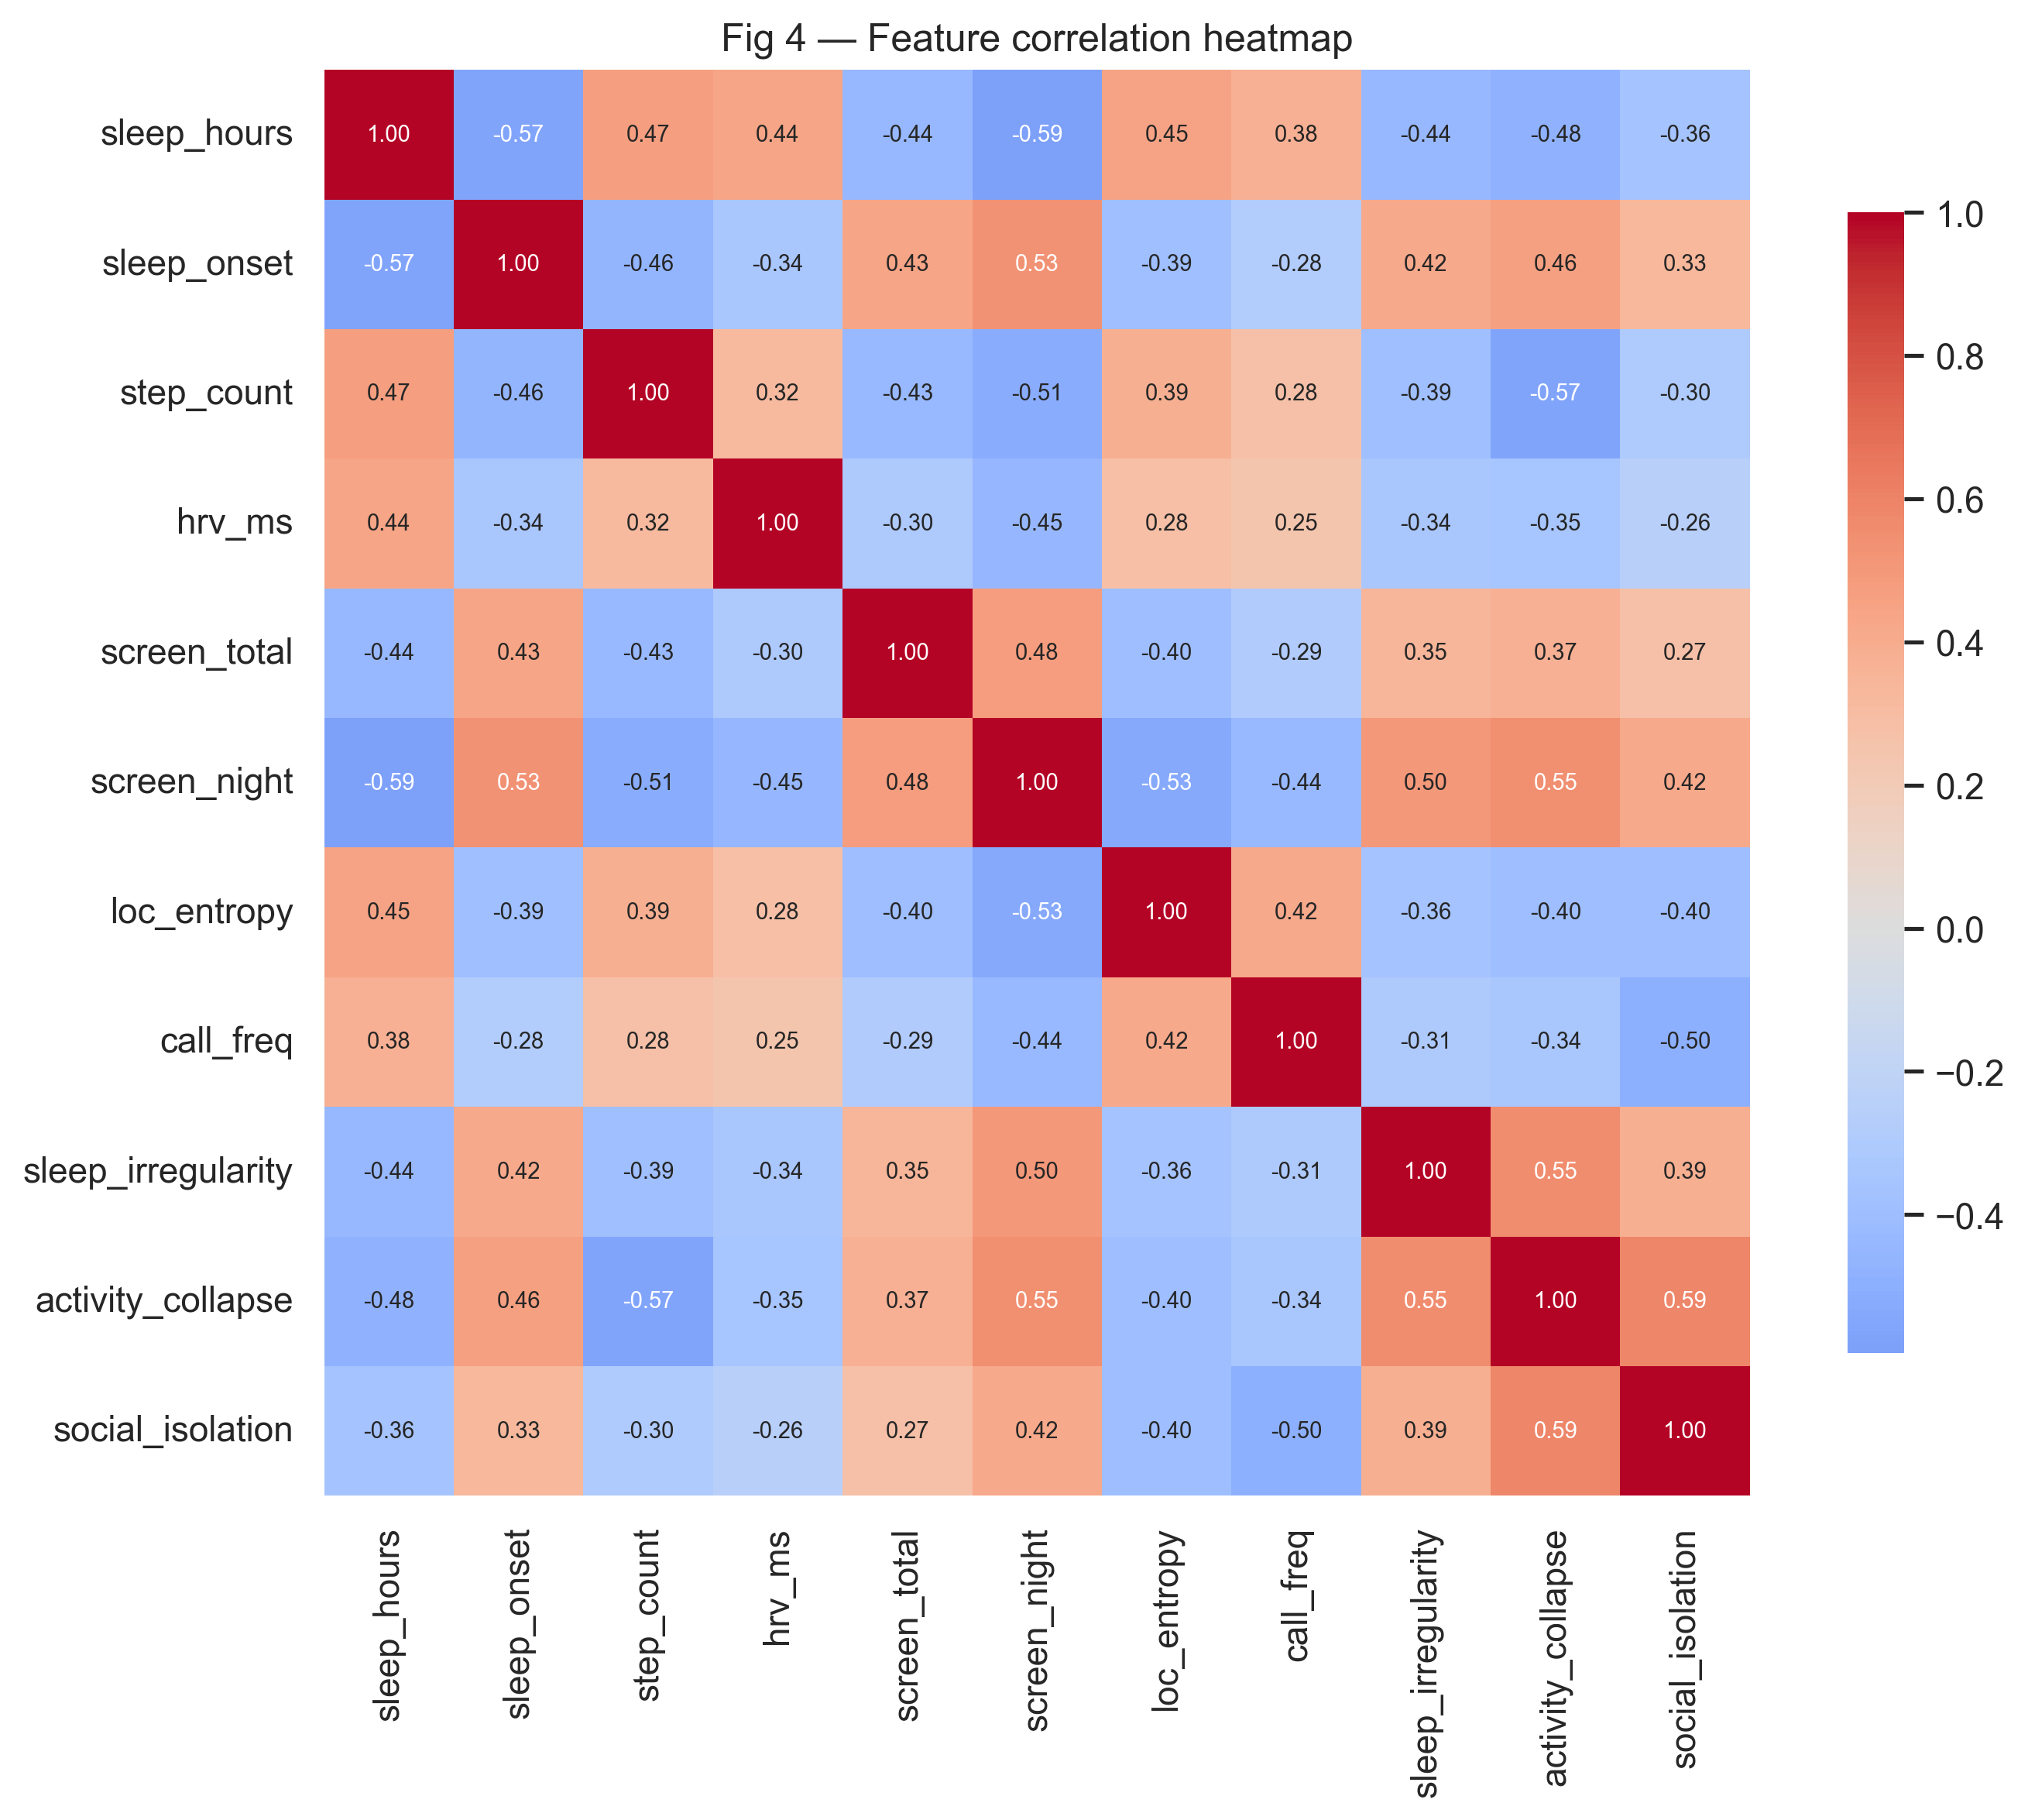

fig5_roc_curves.png


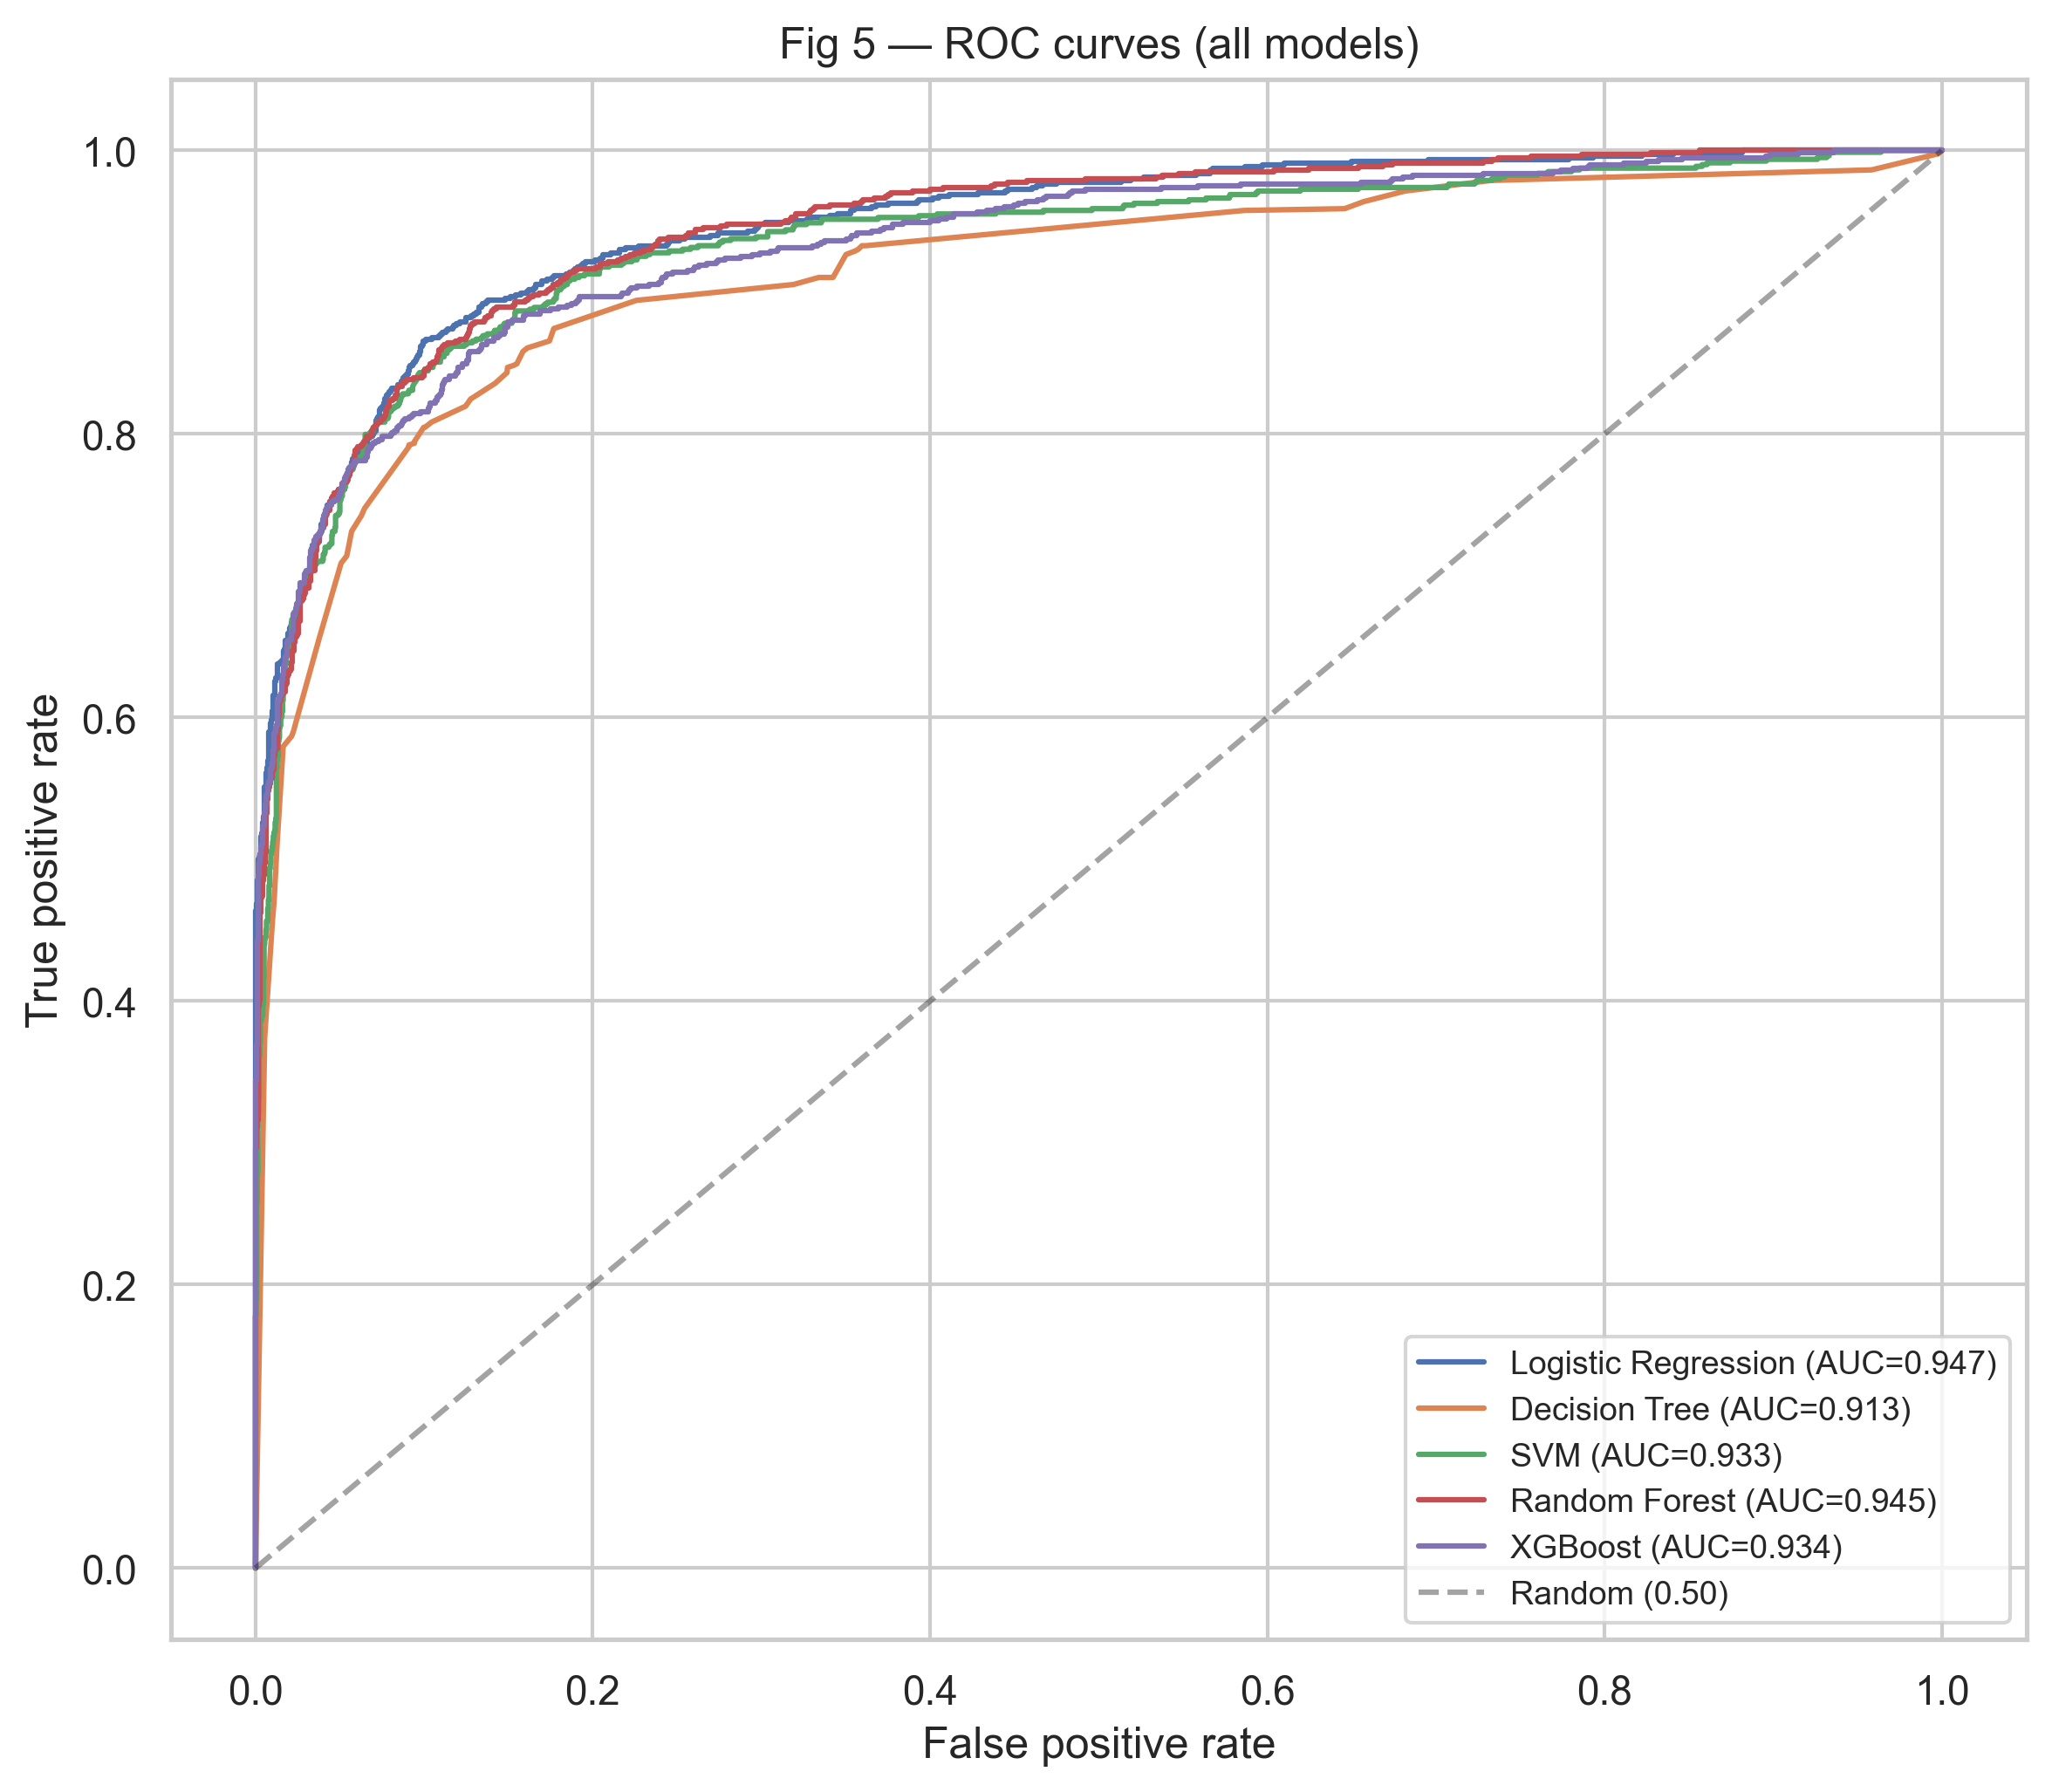

fig6_confusion_matrix.png


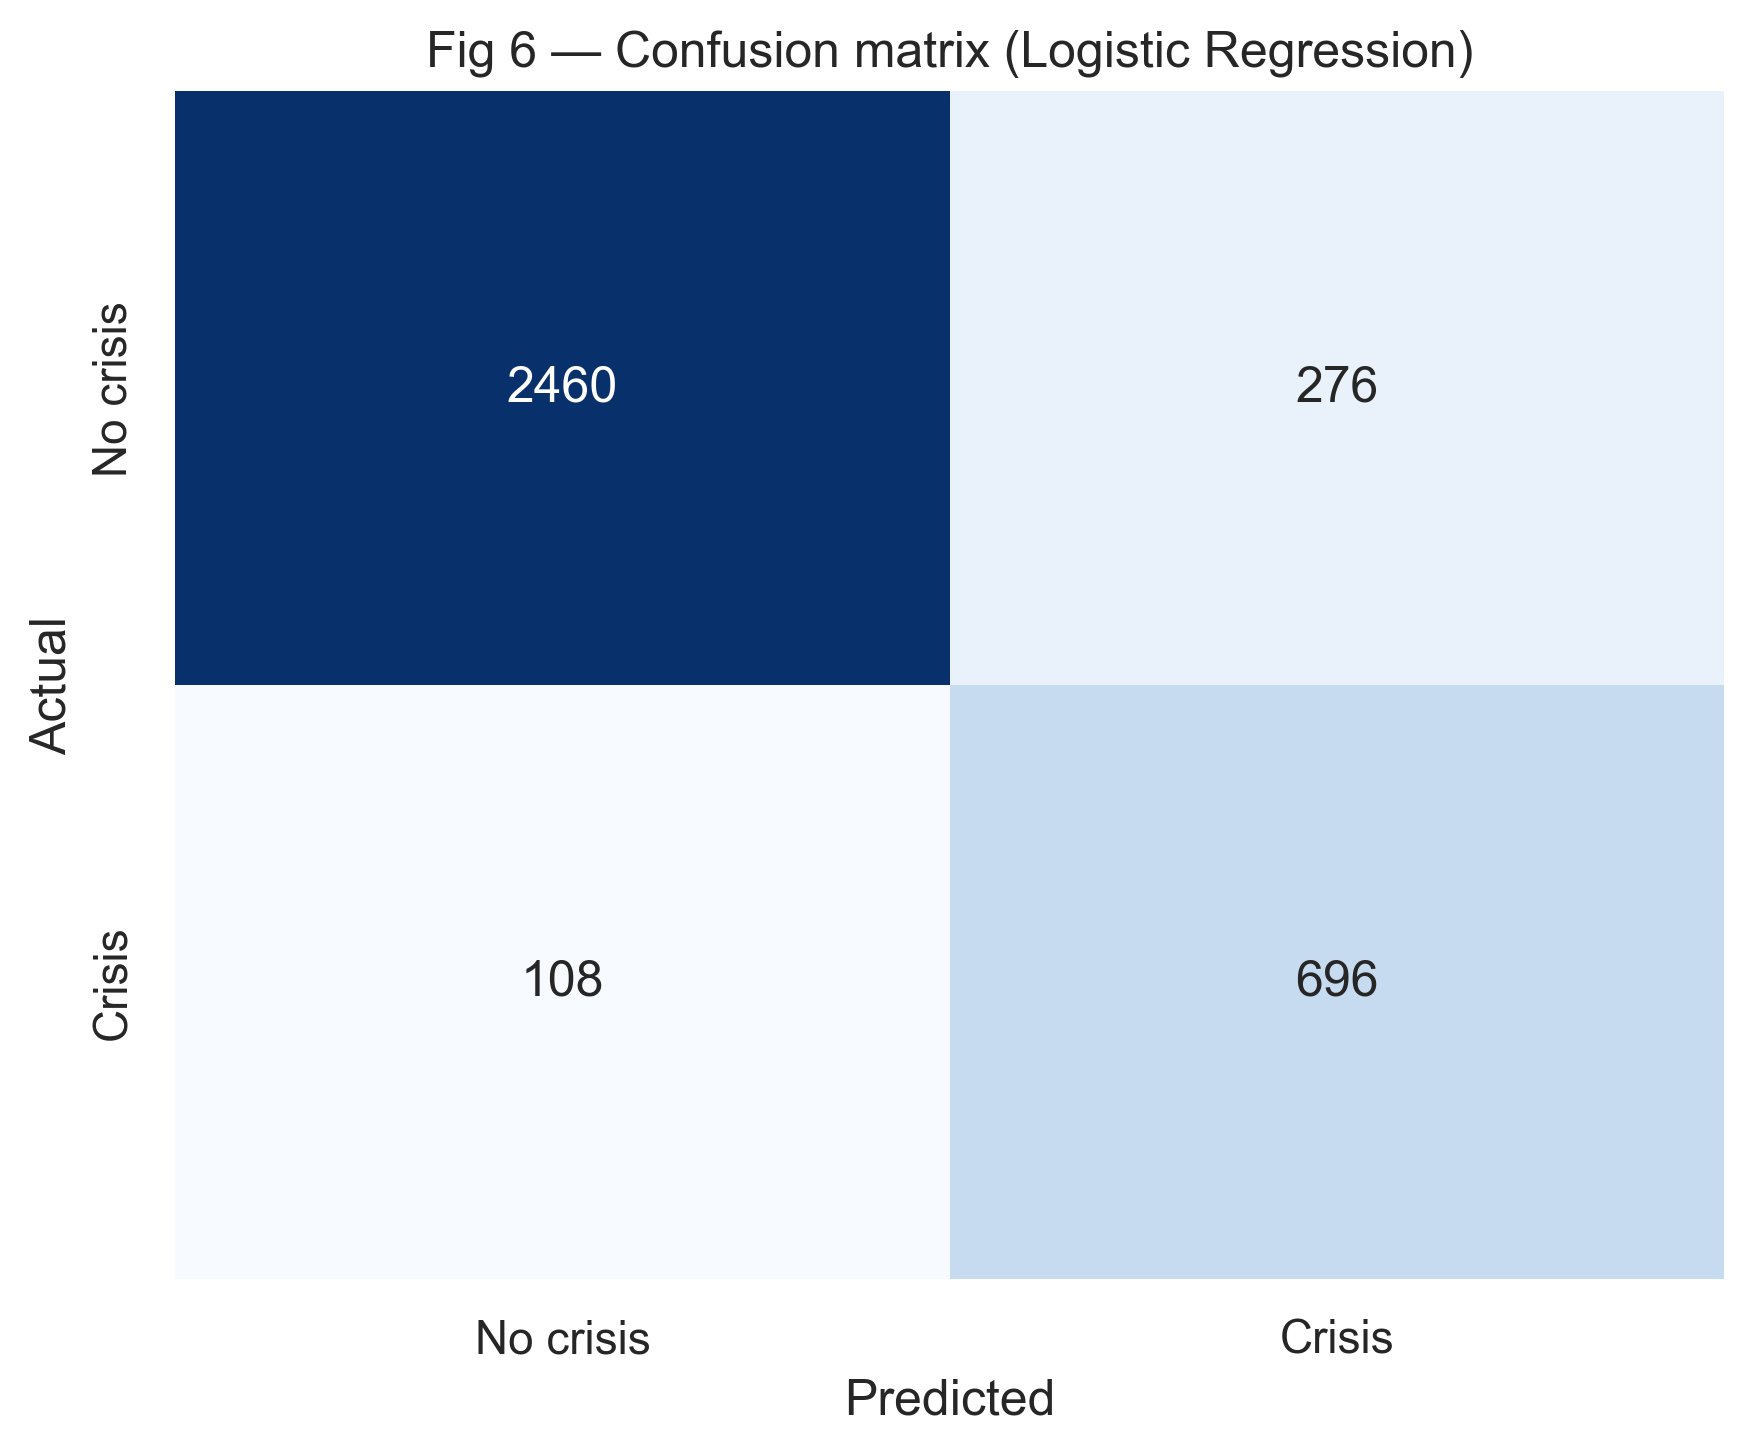

fig7_shap.png


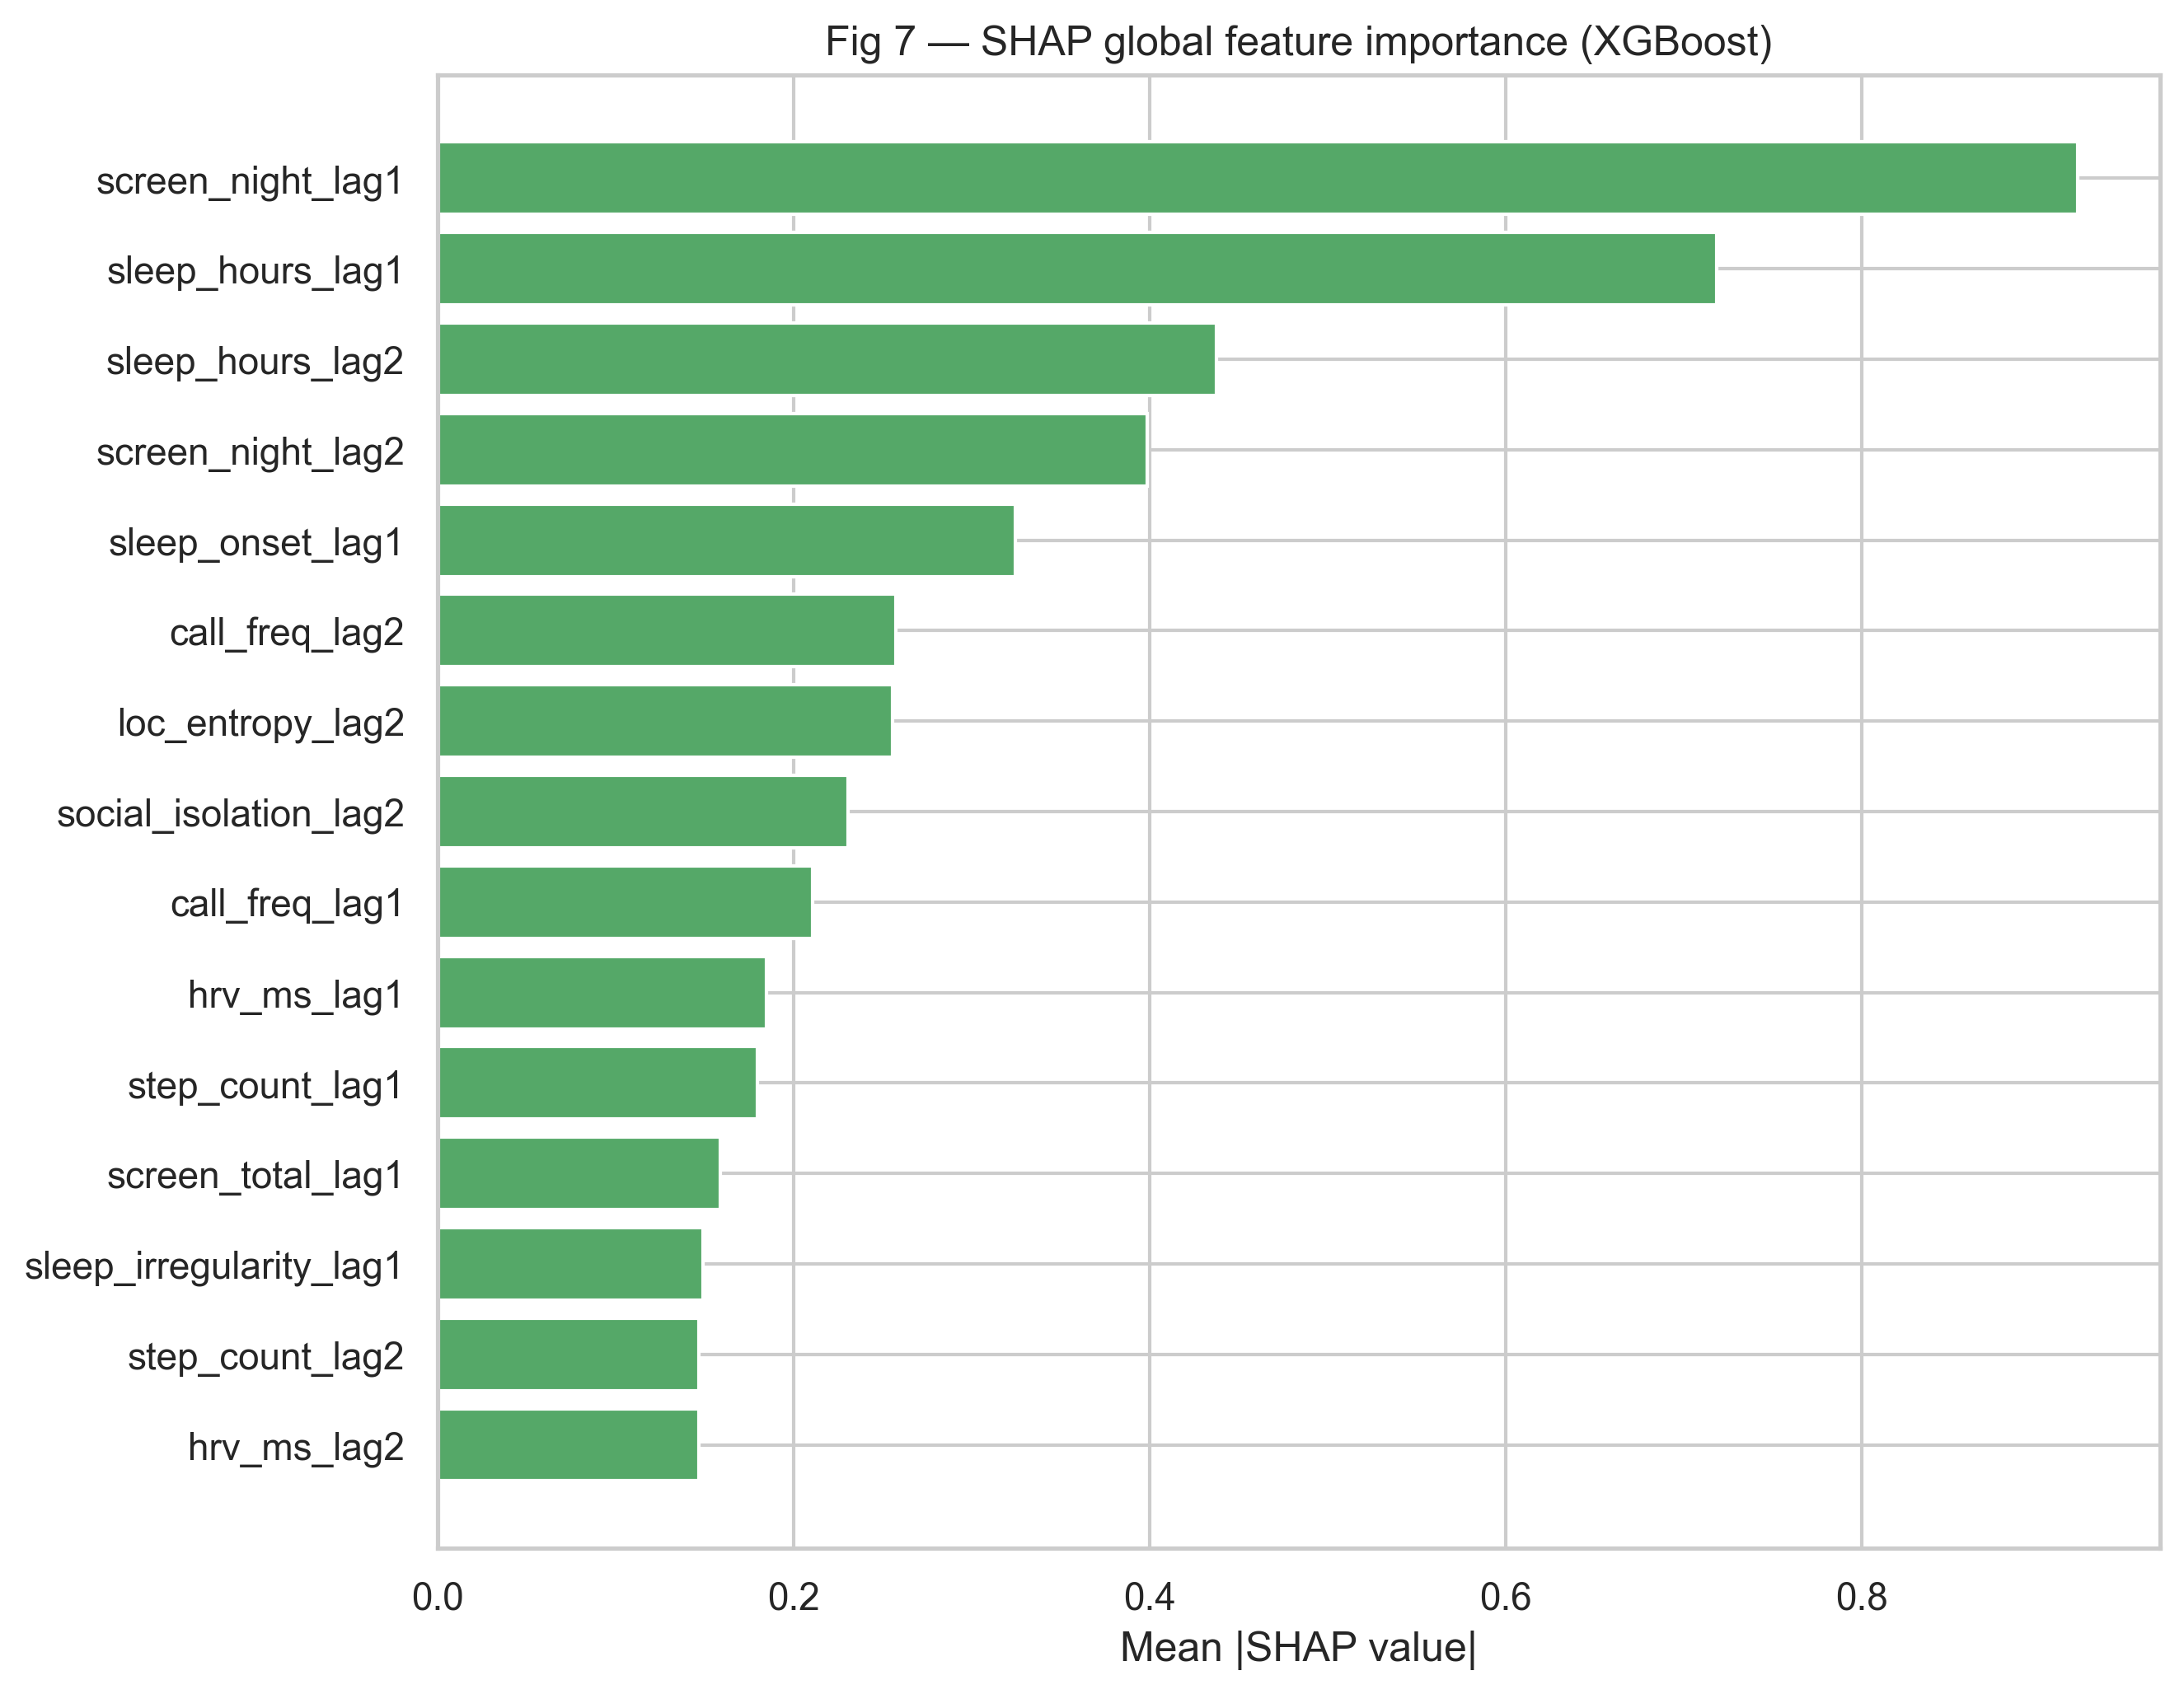

fig8_cross_validation.png


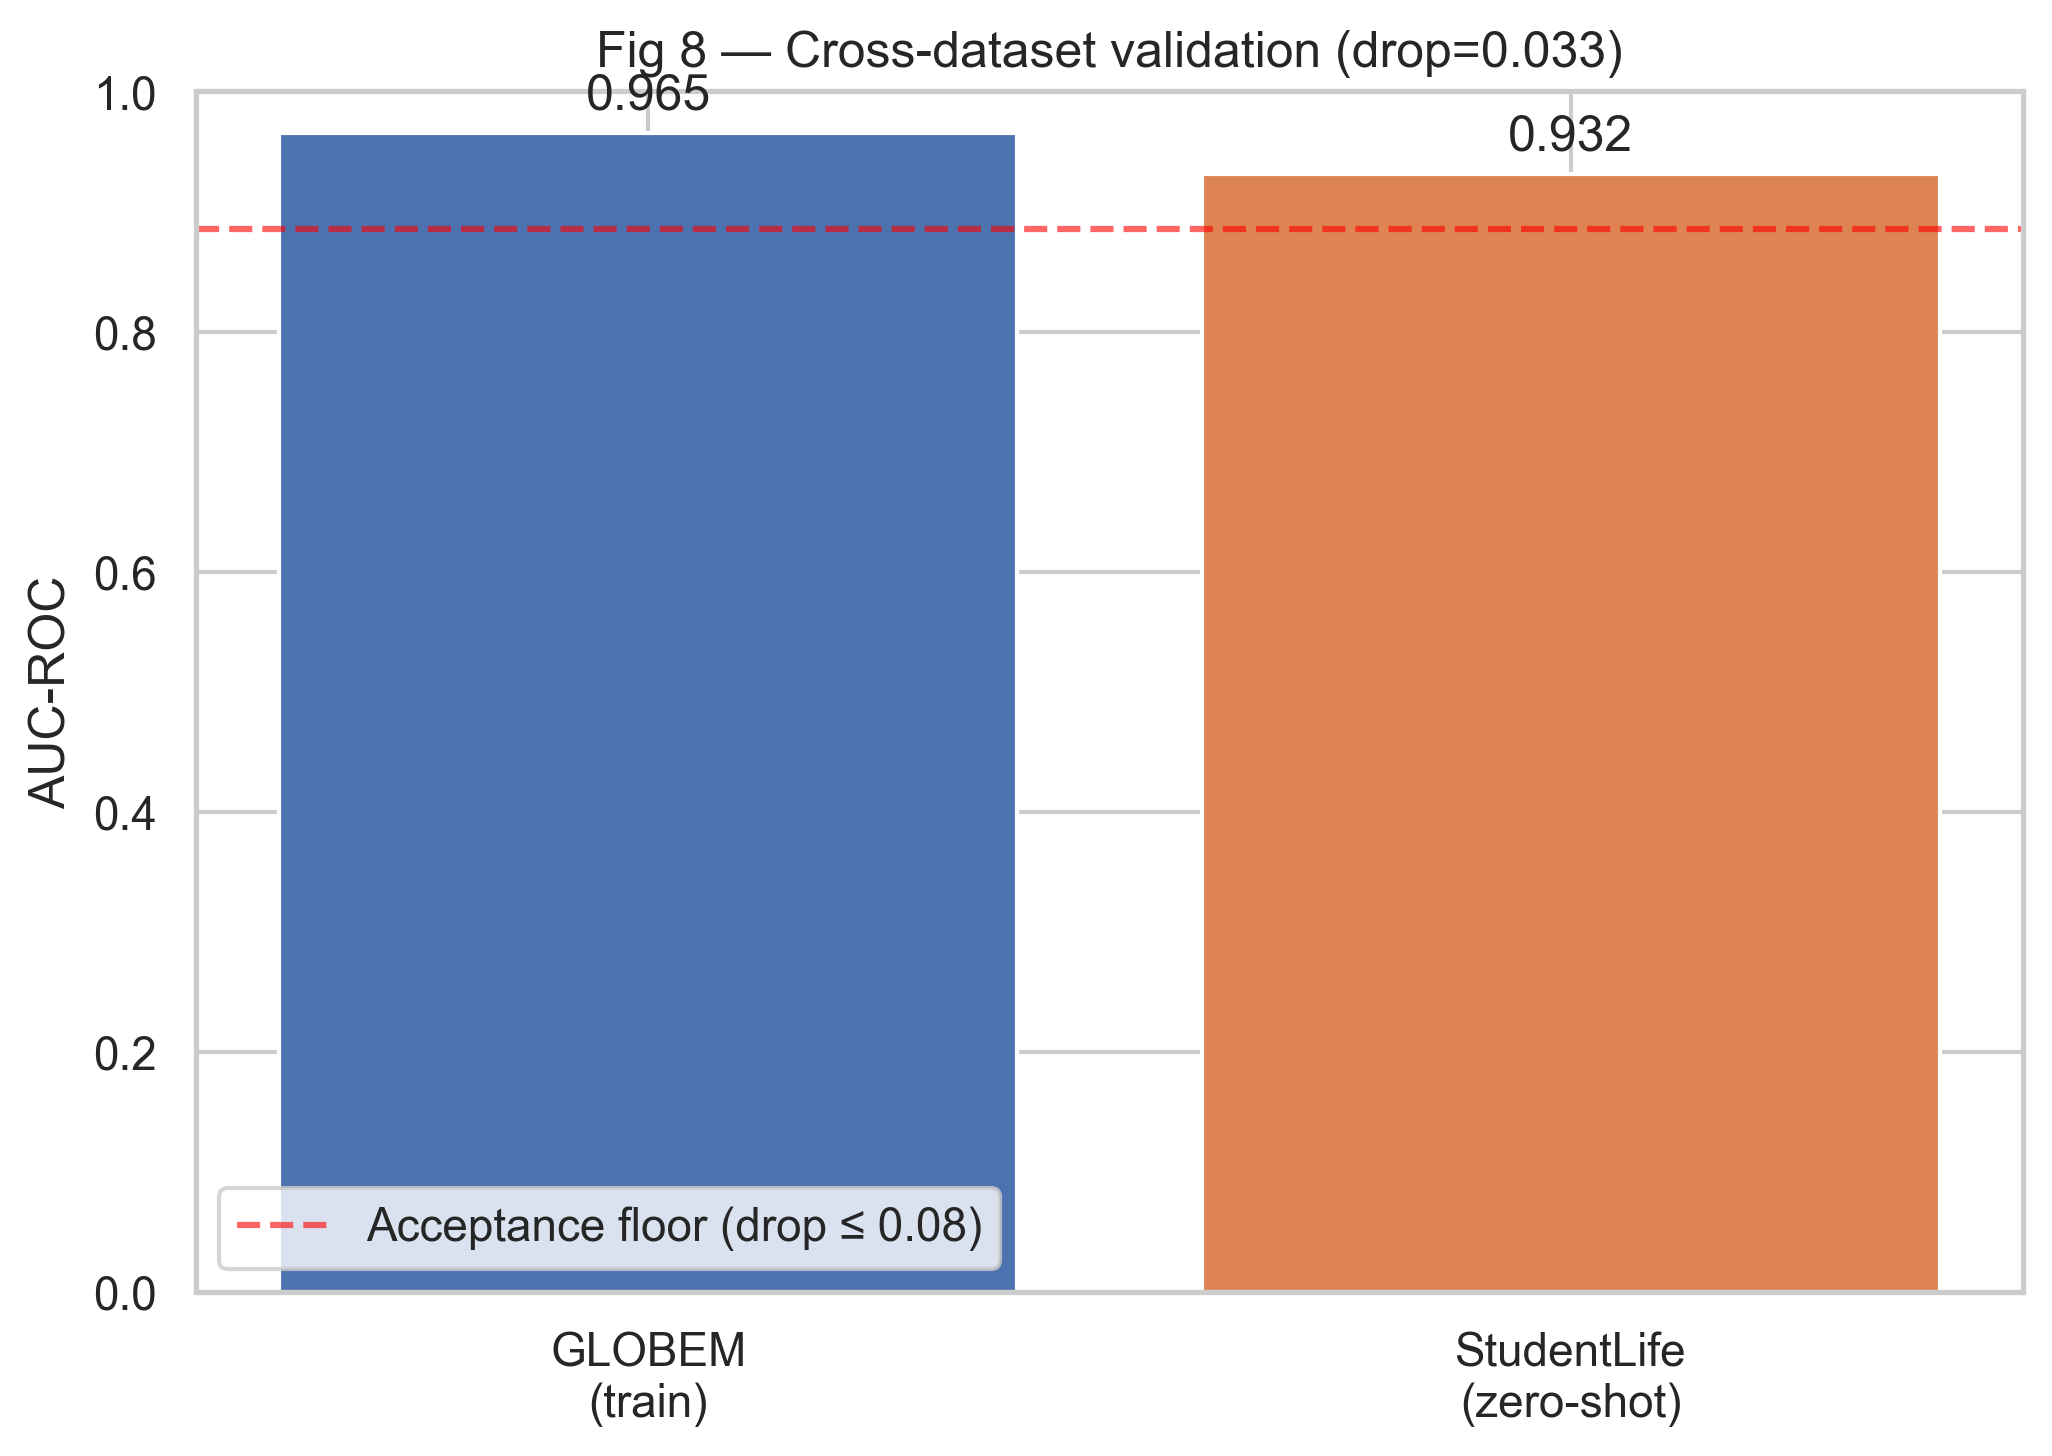

In [25]:
from IPython.display import Image, display
for f in sorted(os.listdir('outputs/figures')):
    if f.endswith('.png'):
        print(f)
        display(Image(filename=os.path.join('outputs/figures', f)))

> 💡 **What just happened:** Everything you need for the paper/presentation is now in `outputs/`. Remember: these numbers are from synthetic data — rerun with real GLOBEM CSVs before reporting final results.

## 🎓 You're done!
You built an end-to-end, explainable, cross-validated crisis-prediction pipeline. Next: register on PhysioNet, download the real GLOBEM CSVs, drop them next to this notebook, and re-run every cell to get real results.

*Decision-support prototype only — not for clinical diagnosis.*